In [1]:
%pip install pandas numpy scikit-learn xgboost scipy


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer 
#Imports a machine learning tool from scikit-learn.
#TfidfVectorizer converts text into numeric feature vectors using TF-IDF, which measures how important a word is in a document relative to the whole dataset

from scipy.sparse import hstack, csr_matrix
#hstack combines multiple feature matrices vertically (used when mixing text and numeric features).
#csr_matrix  Imports and compress sparse matrix functions.
# keeps two data tables like TF-IDF text numbers and structured vitals numbers together , as they as stored in different formats as text and numeric

from xgboost import XGBClassifier
from sklearn.metrics import classification_report, f1_score


In [3]:
#Loading the testing and testing  data

x_train = pd.read_csv("x_train_clean.csv")
y_train_clean = pd.read_csv("y_train_clean.csv").squeeze().astype(int)


x_test = pd.read_csv("x_test_clean.csv")
y_test = pd.read_csv("y_test_clean.csv").squeeze().astype(int)

print(x_train.shape, x_test.shape, y_train_clean.shape, y_test.shape)   
print("Patient overlap:", len(set(x_train["subject_id_x"]) & set(x_test["subject_id_x"])), "(expect 0)")


(334480, 63) (83620, 63) (334480,) (83620,)
Patient overlap: 0 (expect 0)


In [4]:
#  cleaning the data before the model training

columns_to_drop = ['subject_id_x', 'subject_id_y', 'stay_id', 'hadm_id', 'intime', 'outtime', 'disposition']

x_train = x_train.drop(columns=columns_to_drop)
x_test = x_test.drop(columns=columns_to_drop)

x_train['pain'] = pd.to_numeric(x_train['pain'], errors='coerce')
#x_train['pain'] = pd.to_numeric(...)  Converts the pain column to numeric type.
# errors='coerce' if any value is not numeric, it is replaced with NaN

x_test['pain'] = pd.to_numeric(x_test['pain'], errors='coerce')

x_train.shape, x_test.shape



((334480, 56), (83620, 56))

In [5]:
# Separating the datatypes into the two types of features:
# text data gets transformed using TF-IDF
# structured numeric data remains as numeric features
# both are then combined into one final feature matrix

text_train = x_train['chiefcomplaint'].fillna('').astype(str)
#fillna('') replaces missing values with empty strings instead of NaN
#astype(str) ensures every entry is a proper string

text_test = x_test['chiefcomplaint'].fillna('').astype(str)

structured_train = x_train.drop(columns=['chiefcomplaint'])
structured_test = x_test.drop(columns=['chiefcomplaint'])

In [6]:
tfidf = TfidfVectorizer(max_features=1000, stop_words='english')
#TfidfVectorizer converts text into numbers so a machine learning model can understand it.

text_train_tfidf = tfidf.fit_transform(text_train)
#fit_transform learns the vocabulary from the training complaints and converts them into TF-IDF values
text_test_tfidf = tfidf.transform(text_test)
#transform is used on test text, this ensures both train and test use the same word dictionary
text_train_tfidf.shape, text_test_tfidf.shape

((334480, 1000), (83620, 1000))

In [7]:
# cell combines the two feature types into one final matrix for the model

structured_train_sparse = csr_matrix(structured_train.values)
structured_test_sparse = csr_matrix(structured_test.values)

x_train_hybrid = hstack([text_train_tfidf, structured_train_sparse])

# text_train_tfidf 1,000 TF-IDF text numbers, stored in a special compressed format
# 52 vitals/demographics columns, stored as an ordinary pandas table
# sparse" is describing something specific about how the data is stored, not what's in it.

x_test_hybrid = hstack([text_test_tfidf, structured_test_sparse])

#hstack([...]) — "horizontal stack" — literally glues the two tables side by side, 
# placing the text-based columns and the vitals-based columns next to each other in one row, for every patient
#1,000 word-based numbers and 52 vitals/demographic numbers, all as one single row.

x_train_hybrid.shape, x_test_hybrid.shape

((334480, 1055), (83620, 1055))

In [8]:
#rerelabelling for the XGBoost 
# XGBoost needs classes numbered 0–4, not 1–5. 
y_train_xgb = y_train_clean - 1
y_test_xgb = y_test - 1


In [9]:
#Training the hybrid model with weighted Class. 
# As in model B, unweighted class have good result but ignores the ESI 4 & 5  less recall value

sample_weights = y_train_xgb.map(y_train_xgb.value_counts(normalize=True).apply(lambda x: 1/x))

model_hybrid = XGBClassifier(
    objective='multi:softmax',
    num_class=5,
    eval_metric='mlogloss',
    random_state=42
)

model_hybrid.fit(x_train_hybrid, y_train_xgb, sample_weight=sample_weights)


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softmax'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import lo

In [10]:
#Making the Predictions

predictions_hybrid_shifted = model_hybrid.predict(x_test_hybrid)


In [11]:
#Shifting the predictions back to ESI level 1-5

predictions_hybrid = (predictions_hybrid_shifted + 1).astype(int)


In [12]:
#Evaluating
print(classification_report(y_test, predictions_hybrid))
print("Macro F1:", f1_score(y_test, predictions_hybrid, average='macro'))

              precision    recall  f1-score   support

           1       0.50      0.80      0.62      4804
           2       0.61      0.65      0.63     27882
           3       0.79      0.49      0.60     45013
           4       0.28      0.74      0.40      5701
           5       0.04      0.50      0.07       220

    accuracy                           0.58     83620
   macro avg       0.44      0.64      0.46     83620
weighted avg       0.68      0.58      0.60     83620

Macro F1: 0.46406056907486226


In [13]:
# Saving the hybrid model's results, using explicit integer labels for safe key lookups

if 'results' not in globals():
    results = {}

report_hybrid = classification_report(
    y_test, predictions_hybrid, output_dict=True, labels=[1,2,3,4,5], zero_division=0
)

results['Hybrid (TF-IDF + XGBoost, weighted)'] = {
    'macro_f1': f1_score(y_test, predictions_hybrid, average='macro'),
    'recall_esi1': report_hybrid['1']['recall'],
    'recall_esi2': report_hybrid['2']['recall'],
    'recall_esi3': report_hybrid['3']['recall'],
    'recall_esi4': report_hybrid['4']['recall'],
    'recall_esi5': report_hybrid['5']['recall'],
}

results

{'Hybrid (TF-IDF + XGBoost, weighted)': {'macro_f1': 0.46406056907486226,
  'recall_esi1': 0.7953788509575354,
  'recall_esi2': 0.6496664514740693,
  'recall_esi3': 0.4911692177815298,
  'recall_esi4': 0.7368882652166286,
  'recall_esi5': 0.5045454545454545}}


# Hybrid Model C (TF-IDF & Structured Vitals, XGBoost, Class_weighted)

This modek combined presenting_complaint text and structured triage vitals into a single feature set, to test whether the two data type carry complementary information rarther than making other redundant.

Actual Steps:

- Text(Chief complaint) was converted using TD-IDF on the full training set (1000 features), the same settings used in Model A, rather than ClinicalBert- justified by Model A is finding that ClinicalBert did no outperform TF-IDF on this task, while tf-IDF is fast enough to use the complete Dataset

-Structured features were cleaned identically to Model B (ID, timestamp, outcome columns dropped tp prevent leakage; missing vitals handled via median imputation with missing_flag columns).

- In Hybrid Model C : Text and structured features were combined into one matrix (1052 columns per patient-1000 text and 52 structured).

-Trained directly with class weighting. The unweighted class was not repeated, as it completely fails on the rarest classes (ESI 4/5). In Model C repeating that comparision here would not add a new experience.

Results:
Macro F1 =0.461 substantial improvement over Model  A, text only = 0.365 and Model B, structured weighted only = 0.347.
 Notably, ESI 3, had the lower recall (0.49) than the rarer ESI 1,2,4 and 5 classes, that conclude the class weighting strategy successfully prioritised minority class detection, over the majority class performance.

In [14]:
#Loading the two csv file and checking their sizes

subgroup_data = pd.read_csv("x_test_clean.csv")
patients = pd.read_csv("patients.csv") #reads a separate file called patients.csv into a DataFrame called patients

subgroup_data.shape, patients.shape

((83620, 63), (364627, 6))

In [15]:
# Calculating each patients age at the emergency visit

subgroup_data['visit_year'] = pd.to_datetime(subgroup_data['intime']).dt.year
# Extracting the visit year after converting intime into a date

subgroup_data = subgroup_data.merge( 
    patients[['subject_id', 'anchor_age', 'anchor_year']], # adds the patient information from patients 
    left_on='subject_id_x', right_on='subject_id',  # merge matches the patient information with this line
    how='left'                          # keep every row from subgroup_data even if the matching patient information is misiing
)

subgroup_data['age_at_visit'] = subgroup_data['anchor_age'] + (subgroup_data['visit_year'] - subgroup_data['anchor_year'])

subgroup_data['age_at_visit'].describe()

count    83609.000000
mean        52.739621
std         20.484261
min         18.000000
25%         35.000000
50%         53.000000
75%         68.000000
max        101.000000
Name: age_at_visit, dtype: float64

In [16]:
# Removing the row s where the pateient age couldnot ne calculated and keeps tha labels and predictions aligned

valid_mask = subgroup_data['age_at_visit'].notna()
# Creating the boolean mask  true for age_at_visit exist and false for age__at_visit is missing

subgroup_data_complete = subgroup_data[valid_mask].reset_index(drop=True)
# keeps only rows with valid ages and resets the row numbers from 0 onward

y_test_subgroup = y_test[valid_mask].reset_index(drop=True)
#select the true esi labels for the same valid row and resets theri index
predictions_hybrid_subgroup = predictions_hybrid[valid_mask]
#selects the model predictions for those same row. since predictions_hybrid is a numpy array, it does not need index resetting

len(subgroup_data_complete), len(y_test_subgroup), len(predictions_hybrid_subgroup)

(83609, 83609, 83609)

In [17]:
#Adding the actual and predicted esi values to the patient dataframe then displaying the first 10 rows

subgroup_data_complete['true_esi'] = y_test_subgroup
subgroup_data_complete['predicted_esi'] = predictions_hybrid_subgroup

subgroup_data_complete[['true_esi', 'predicted_esi', 'age_at_visit', 'gender']].head(10)

,true_esi,predicted_esi,age_at_visit,gender
0,3,3,25.0,0
1,3,4,25.0,0
2,3,3,25.0,0
3,3,4,59.0,1
4,3,3,54.0,1
5,2,2,78.0,1
6,2,2,76.0,1
7,1,1,80.0,1
8,3,2,78.0,1
9,3,4,77.0,1


In [18]:
#grouping the patients into the age ranges

subgroup_data_complete['age_band'] = pd.cut(     #pd.cut() takes the numeric and age_at_visit values and assigns each patient to an age category 
# It is used inlater cell at 41 as age_band for subgroup analysis
    subgroup_data_complete['age_at_visit'],
    bins=[18, 35, 50, 65, 80, 103],
    labels=['18-34', '35-49', '50-64', '65-79', '80+'],
    include_lowest=True
)

subgroup_data_complete['age_band'].value_counts()
#the new age age categoreis area stored in a column named age_band and count how many patients belong to each age group

age_band
18-34    21597
50-64    21317
35-49    16193
65-79    15562
80+       8940
Name: count, dtype: int64

In [19]:
#measuring how accurate the model is for each group

def recall_for_group(df):  # defines the function that receives one group of patients as a dataframe
    correct = (df['true_esi'] == df['predicted_esi']).sum()
    #compares the actual esi level with the predicted esi level and .sum() counts the true values where predictions are correct
    total = len(df) # count the number of patients in the age group
    return correct / total  # accuracy=correct predictions/total patients

age_band_accuracy = subgroup_data_complete.groupby('age_band').apply(recall_for_group)
age_band_accuracy

age_band
18-34    0.561235
35-49    0.572840
50-64    0.578224
65-79    0.589449
80+      0.610291
dtype: float64

In [20]:
gender_accuracy = subgroup_data_complete.groupby('gender').apply(recall_for_group)
gender_accuracy

gender
0    0.573082
1    0.582619
dtype: float64

In [21]:
#measuring how often the model’s predictions match the true ESI level for each race category. It does not train or change the model.
race_cols = [col for col in subgroup_data_complete.columns if col.startswith('race_')]
#race_cols finds encoded columns whose names start with race_.
subgroup_data_complete['race_label'] = subgroup_data_complete[race_cols].idxmax(axis=1).str.replace('race_', '')
#idxmax(axis=1) picks the race column with the largest value for each patient. Removing race_ leaves the race label, which is stored in race_label.

race_accuracy = subgroup_data_complete.groupby('race_label').apply(recall_for_group)
race_counts = subgroup_data_complete['race_label'].value_counts()
#groupby('race_label').apply(recall_for_group) calculates the score for each race group. recall_for_group counts exact matches between true_esi and predicted_esi, so this is accuracy, not recall.
#race_counts counts patients in each group.
pd.DataFrame({'accuracy': race_accuracy, 'count': race_counts}).sort_values('count', ascending=False)
#The final table shows accuracy and patient count, sorted from largest group to smallest.

,accuracy,count
race_label,,
WHITE,0.589043,44703
BLACK/AFRICAN AMERICAN,0.558800,15927
OTHER,0.557754,4043
HISPANIC/LATINO - PUERTO RICAN,0.579148,2628
HISPANIC/LATINO - DOMINICAN,0.589212,1687
WHITE - OTHER EUROPEAN,0.566366,1665
ASIAN - CHINESE,0.589185,1424
BLACK/CAPE VERDEAN,0.573456,1409
ASIAN,0.553130,1374


In [22]:
#Before in cell 7, we use 1,052 numbers per patient (1,000 word-based + 52 structured) and outputs a triage prediction. 
# SHAP answers: for a given prediction, which of those 1,052 numbers actually pushed the model toward that answer, and by how much?

%pip install shap


Note: you may need to restart the kernel to use updated packages.


In [23]:
#combined feature matrix just has 1,052 anonymous columns

text_feature_names = tfidf.get_feature_names_out()
structured_feature_names = structured_train.columns.tolist()

all_feature_names = list(text_feature_names) + structured_feature_names

len(all_feature_names)

1055

In [24]:
#  SHAP to explain which features influenced the hybrid XGBoost model’s predictions.
import shap

sample_size = 2000
x_sample = x_test_hybrid[:sample_size]

explainer = shap.TreeExplainer(model_hybrid)
shap_values = explainer.shap_values(x_sample)

len(shap_values), shap_values[0].shape
#5: one SHAP matrix for each ESI class
#2000: the number of explained patients
#number_of_features - 1052 : the number of hybrid text and structured features

c:\Users\harik\anaconda3\envs\aaih8801\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(2000, (1055, 5))

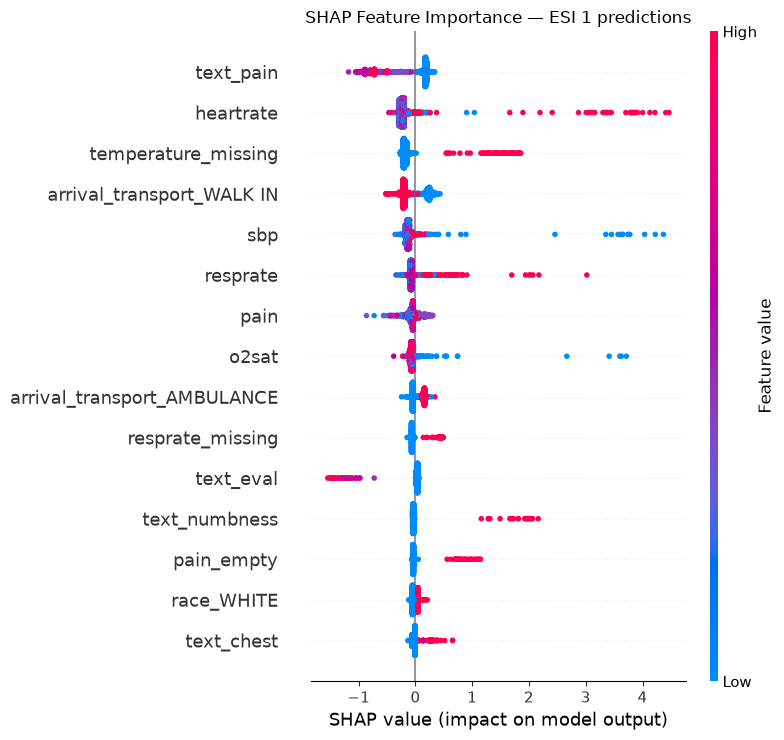

In [25]:
import matplotlib.pyplot as plt

# Fix the naming collision first — label text features distinctly
text_feature_names_labeled = ['text_' + name for name in tfidf.get_feature_names_out()]
all_feature_names = list(text_feature_names_labeled) + structured_feature_names

# Then convert to dense and plot
x_sample_dense = x_sample.toarray()

shap.summary_plot(
    shap_values[:, :, 0],  #shap_values[:, :, 0] selects SHAP values for every sampled patient and feature, for class index 0. Since, ESI labels shifts from 1–5 to 0–4 for XGBoost, class 0 corresponds to ESI 1.
    x_sample_dense,        #x_sample_dense provides the feature values for those same patients, which SHAP uses to color the points.
    feature_names=all_feature_names,    #labels the plot’s features.
    max_display=15,                     #displays the 15 most influential features.   
    show=False                          # lets the following code add a title, save the figure, and then display it.
)
plt.title("SHAP Feature Importance — ESI 1 predictions")  #adds the title “SHAP Feature Importance — ESI 1 predictions.”
plt.tight_layout()                                         # plt.tight_layout() adjusts spacing so labels and the title are less likely to be clipped.
plt.savefig("shap_esi1.png", dpi=150)                       # saves the figure as shap_esi1.png in the notebook’s current working directory at 150 DPI.
plt.show()                                                  # plt.show() displays the figue as below

Shap analysis of the hybrid model ESI 2 prediction identified heart rare, systolic blood pressure, and oxygen saruration as the most influential structured features, with abnormal values (evaluated heart rate; low blood pressure and oxygen saturation) consistently pushing predictions toward the most acuity level - consistent with established clinical indicators of physiological instability.
 Missingness itself carried predictive signal: missing temperature and respiratory rate readings were  associated  with increased likelihood of an ESI 1 prediction, plausibly reflecting that  sufficiently unstable  patients may no have a complete set of vitals recorded promptly.
  Among text features, complaint terms including 'chest', 'numbness', and 'allergic' were associated with higher predicted acuity. Notabaly, race_WHite appeared among the fifteen most influential features for ESI 1 predictions, corroborting the subgroup_level accuracy difference identified between White and Black/African patients  and warranting further fairness investigation before any real_world application.

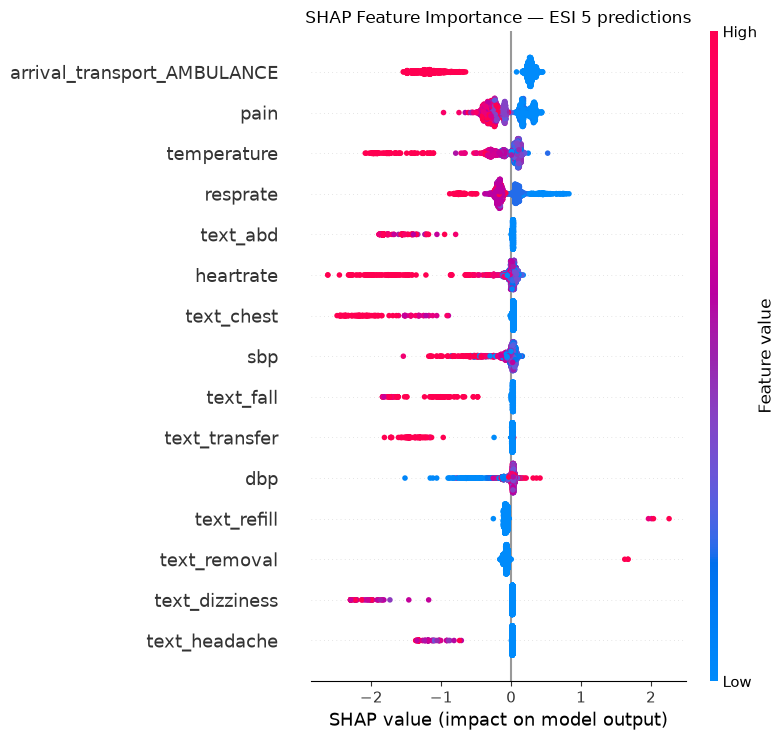

In [26]:
#Run ESI 5 for the actual contrast
shap.summary_plot(
    shap_values[:, :, 4],
    x_sample_dense,
    feature_names=all_feature_names,
    max_display=15,
    show=False
)
plt.title("SHAP Feature Importance — ESI 5 predictions")
plt.tight_layout()
plt.savefig("shap_esi5.png", dpi=150)
plt.show()

This is a SHAP summary plot for the model’s ESI 5 predictions. ESI 5 is the least urgent category.

Each dot represents one patient. The rows are features, ranked roughly from most influential at the top to least influential at the bottom. arrival_transport_AMBULANCE has the greatest overall influence among the features shown.
The horizontal position shows the feature’s effect on the model’s ESI 5 score. A dot to the right pushes the model more toward ESI 5; a dot to the left pushes it away. Farther from zero means a larger effect. This is a model score, not necessarily a probability.
The color shows the feature value: pink means high and blue means low. For binary text_... or transport flags, high usually means the flag is present (1) and low means absent (0).
For example, pink dots for arrival_transport_AMBULANCE mostly fall left of zero, so ambulance arrival generally pushes the model away from ESI 5. For text_refill, some pink dots are far to the right, so that feature can push predictions toward ESI 5.

This describes patterns the model learned; it does not show that a feature causes a triage level. Also, this plot explains ESI 5 specifically, not the model’s performance across every ESI category.

In [27]:
#saving and verifing the hybrid model’s test predictions.
import os
from sklearn.metrics import f1_score
 
os.makedirs("results", exist_ok=True) #  creates a results folder if needed.
test_stay_ids = pd.read_csv("x_test_clean.csv", usecols=["stay_id"])["stay_id"].to_numpy() #reads the test patients’ stay_id values in CSV order.

assert len(test_stay_ids) == len(y_test) == len(predictions_hybrid), "lengths differ" # checks that the IDs, true labels, and predictions have the same number of rows. If not, it stops with "lengths differ".
np.savez("results/hybrid_weighted.npz", y_true=y_test.values,
         y_pred=np.asarray(predictions_hybrid), stay_id=test_stay_ids)
 
d = np.load("results/hybrid_weighted.npz")                       # .npz file can then be used by later cells to compare models or analyze specific patients.
print(d["y_true"].shape, d["y_pred"].shape, d["stay_id"].shape,
      f1_score(d["y_true"], d["y_pred"], average="macro"))
 

(83620,) (83620,) (83620,) 0.46406056907486226


Text-only (TF-IDF)           macro F1 = 0.3656
Structured (unweighted)      macro F1 = 0.3689
Structured (class-weighted)  macro F1 = 0.3485
Hybrid (weighted)            macro F1 = 0.4641


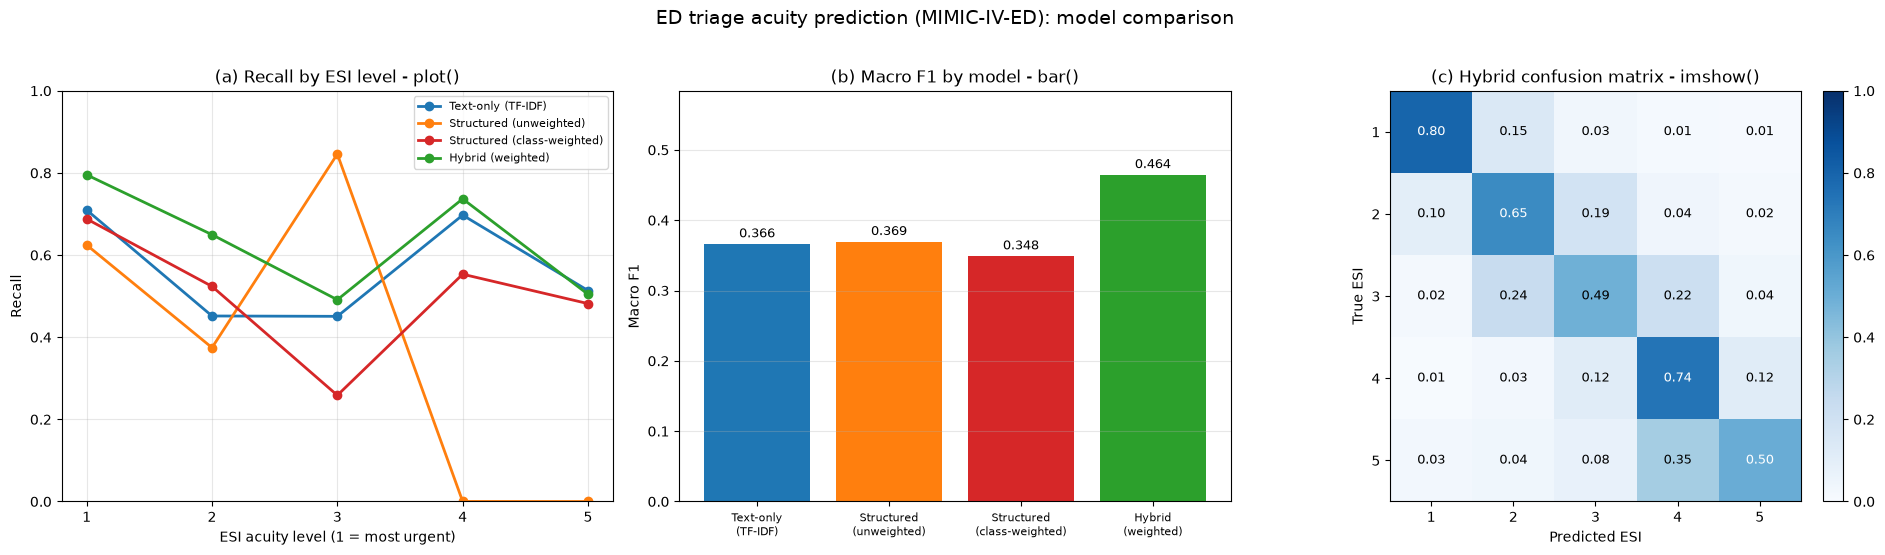

In [28]:
# loading saved predictions from the all models and creates a comparison figure
#the three figures, ALL models
# plot() recall by ESI level | bar() macro F1 | imshow() hybrid confusion matrix

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
 
ESI = [1, 2, 3, 4, 5]
files = {"Text-only (TF-IDF)": "results/text_only.npz",   # Importing the saved predictions from the three models for comparison
         "Structured (unweighted)": "results/structured_unweighted.npz",
         "Structured (class-weighted)": "results/structured_weighted.npz",
         "Hybrid (weighted)": "results/hybrid_weighted.npz"}
colours = {"Text-only (TF-IDF)": "tab:blue", "Structured (unweighted)": "tab:orange",
           "Structured (class-weighted)": "tab:red", "Hybrid (weighted)": "tab:green"}
 
runs = {} # check which of the four .npz files exist, and load the true and predicted labels for each model into runs
for name, path in files.items():
    if os.path.exists(path):
        z = np.load(path)
        runs[name] = (z["y_true"].astype(int), z["y_pred"].astype(int))
    else:
        print("Missing file (run that notebook first):", path)
 
res = {} # compute recall by ESI level and macro F1 for each model
for name, (yt, yp) in runs.items():
    p, r, f, _ = precision_recall_fscore_support(yt, yp, labels=ESI, zero_division=0)
    res[name] = {"recall": r, "macro_f1": f1_score(yt, yp, average="macro")}
    print(f"{name:28s} macro F1 = {res[name]['macro_f1']:.4f}")
 
fig, axes = plt.subplots(1, 3, figsize=(19, 5.4)) # create subplots for the three figures
 
ax = axes[0]                                                       # (a) plot()
#Recall by ESI: compares how often each model correctly identifies patients in each true ESI class.
for name, r in res.items(): # draws a line for each model, showing how recall varies by ESI level
    ax.plot(ESI, r["recall"], marker="o", linewidth=2, label=name, color=colours[name])
ax.set_xticks(ESI); ax.set_ylim(0, 1)
ax.set_xlabel("ESI acuity level (1 = most urgent)"); ax.set_ylabel("Recall")
ax.set_title("(a) Recall by ESI level - plot()"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
 
ax = axes[1]                                                      # (b) bar()
vals = [r["macro_f1"] for r in res.values()] # compares overall class-balanced scores.
bars = ax.bar([n.replace(" (", "\n(") for n in res], vals, color=[colours[n] for n in res])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylabel("Macro F1"); ax.set_ylim(0, max(vals) + 0.12)
ax.set_title("(b) Macro F1 by model - bar()"); ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="x", labelsize=8)
 
ax = axes[2]                                                       # (c) imshow(): hybrid confusion matrix
# shows the hybrid model’s predictions by true class; rows are true ESI and columns are predicted ESI. Each row is normalized to proportions.
yt, yp = runs["Hybrid (weighted)"]
cm = confusion_matrix(yt, yp, labels=ESI, normalize="true")
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(ESI); ax.set_yticks(range(5)); ax.set_yticklabels(ESI)
ax.set_xlabel("Predicted ESI"); ax.set_ylabel("True ESI")
ax.set_title("(c) Hybrid confusion matrix - imshow()")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
 
plt.suptitle("ED triage acuity prediction (MIMIC-IV-ED): model comparison", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("Figure_Hybrid_Model_C.png", dpi=300, bbox_inches="tight")
plt.show()
 

In [29]:
#creating a subgroup equity table for the hybrid model. It compares results across age bands, sex, and race groups. It analyzes existing predictions;

#wilson(k, n) calculates a 95% confidence interval for a proportion.
#  Here, k is the number of under-triaged urgent patients and n is the number of urgent patients in that group. If n is zero, it returns missing values.
def wilson(k, n, z=1.96):
    """95% confidence interval for a proportion k/n."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (centre - half, centre + half)
 
def subgroup_table(df, group_col): #subgroup_table(df, group_col) processes each group in a column such as age_band, sex, or race_group.
    rows = [] # rows will hold the results for each group. It starts as an empty list.
    for g, d in df.groupby(group_col, observed=True): 
        # loops through each group g in the specified column group_col, with d being the corresponding subset of the DataFrame for that group.
        yt, yp = d["true_esi"].to_numpy().astype(int), d["predicted_esi"].to_numpy().astype(int)
        urgent = yt <= 2                                        # urgent = yt <= 2 identifies actual ESI 1–2 patients
        n_urgent = int(urgent.sum())
        under = int((yp[urgent] >= 3).sum())                    # under counts how many of them the model predicted as ESI 3–5.
        lo, hi = wilson(under, n_urgent)
        rows.append({group_col: g, "n": len(d), "n_urgent_ESI1-2": n_urgent,  # AGE_BAND, SEX, RACE_GROUP 
        #Each row reports the group’s patient count, urgent-patient count, exact-match accuracy, macro F1, under-triage rate and confidence interval, and over-triage rate.
                     "accuracy": (yt == yp).mean(),
                     "macro_f1": f1_score(yt, yp, labels=np.unique(yt), average="macro", zero_division=0),
                     "under_triage_rate": under / n_urgent if n_urgent else np.nan,
                     "under_95CI": f"{lo:.2f}-{hi:.2f}" if n_urgent else "",
                     "over_triage_rate": float((yp[yt >= 3] <= 2).mean())})   # actual ESI 3-5 predicted ESI 1-2
    return pd.DataFrame(rows).round(3) # returns a DataFrame with the subgroup analysis results, rounded to three decimal places.
 # here The actual age_band column is created earlier, in cell 25, using pd.cut() on each patient’s age_at_visit.
 ##grouping the patients into the age ranges 'title' cell 25
 
# readable gender labels (IN data: M=0, F=1)
# maps the gender column to readable labels, creating a new column called sex.
subgroup_data_complete["sex"] = subgroup_data_complete["gender"].map({0: "Male", 1: "Female"}) 
 
# one race label per patient; check that nobody has all race columns = 0 (idxmax would then mislabel them)
race_cols = [
    c for c in subgroup_data_complete.columns
    if c.startswith("race_") and pd.api.types.is_numeric_dtype(subgroup_data_complete[c])
]
print("Rows with no race column set:", int((subgroup_data_complete[race_cols].sum(axis=1) == 0).sum()))

race_raw = subgroup_data_complete[race_cols].idxmax(axis=1).str.replace("race_", "", regex=False) 
# race_raw finds the race column with the largest value for each patient, removes the "race_" prefix, and stores the result in a Series called race_raw.
 
def race_group(s):
    if s.startswith("WHITE"):
        return "White"
    if s.startswith("BLACK"):
        return "Black/African American"
    if s.startswith("HISPANIC") or s.startswith("SOUTH AMERICAN"):
        return "Hispanic/Latino"
    if s.startswith("ASIAN") or s.startswith("NATIVE HAWAIIAN"):
        return "Asian/Pacific Islander"
    return "Other/Unknown"
subgroup_data_complete["race_group"] = race_raw.map(race_group) 
# subgroup_data_complete["race_group"] applies the race_group function to each patient’s race_raw value, creating a new column called race_group with the simplified race categories.
 
for col in ["age_band", "sex", "race_group"]: # for each of the three subgroup columns, it prints a header and then calls subgroup_table to compute and display the subgroup analysis results.
    print(f"\n=== by {col} ===")
    print(subgroup_table(subgroup_data_complete, col).to_string(index=False))
 

Rows with no race column set: 0

=== by age_band ===
age_band     n  n_urgent_ESI1-2  accuracy  macro_f1  under_triage_rate under_95CI  over_triage_rate
   18-34 21597             5824     0.561     0.465              0.284  0.27-0.30             0.178
   35-49 16193             5344     0.573     0.452              0.270  0.26-0.28             0.186
   50-64 21317             8671     0.578     0.453              0.237  0.23-0.25             0.227
   65-79 15562             7690     0.589     0.445              0.181  0.17-0.19             0.312
     80+  8940             5153     0.610     0.413              0.141  0.13-0.15             0.412

=== by sex ===
   sex     n  n_urgent_ESI1-2  accuracy  macro_f1  under_triage_rate under_95CI  over_triage_rate
Female 45843            16554     0.583     0.461              0.240  0.23-0.25             0.221
  Male 37766            16128     0.573     0.466              0.205  0.20-0.21             0.243

=== by race_group ===
            ra


=== under-triage of ESI 1-2 patients by race_group (crude vs age-standardised) ===
                        n_urgent  crude_under_triage  age_standardised
Asian/Pacific Islander      1291               0.244             0.234
Black/African American      6017               0.265             0.258
Hispanic/Latino             1968               0.286             0.266
Other/Unknown               2400               0.226             0.214
White                      21006               0.203             0.208

=== under-triage of ESI 1-2 patients by sex (crude vs age-standardised) ===
        n_urgent  crude_under_triage  age_standardised
Female     16554               0.240             0.241
Male       16128               0.205             0.204


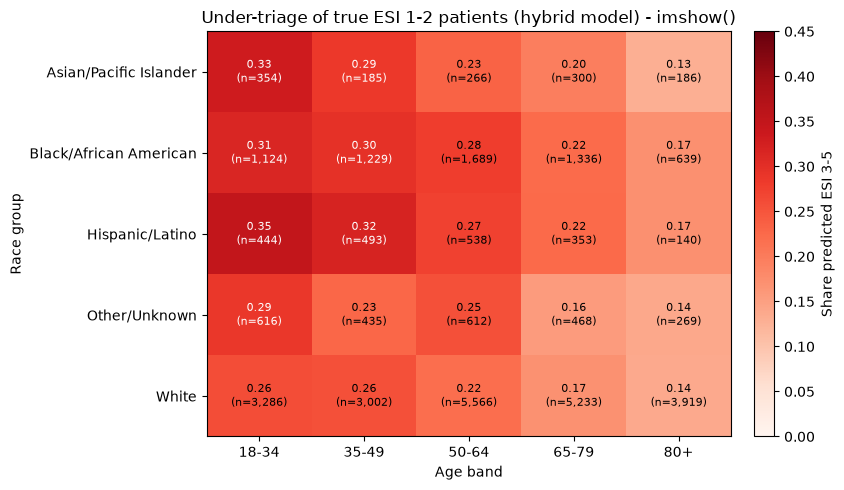

In [30]:
 #checking under-triage among the most urgent patients and comparing it across race and sex. It analyzes existing predictions
 #subgroup_data_complete with true_esi, predicted_esi, age_band, sex, race_group. 

 
#0 AS urgent patients only (true ESI 1-2); 1 AS "under" = predicted ESI 3-5 
urg = subgroup_data_complete[subgroup_data_complete["true_esi"] <= 2].copy()
 #urg contains only patients whose true ESI is 1 or 2, and .copy() ensures that urg is a separate DataFrame, not just a view of the original.
urg["under"] = (urg["predicted_esi"] >= 3).astype(int) 
# under is a new column in urg that is 1 if the model predicted ESI 3-5 (under-triage) and 0 if it predicted ESI 1-2 (correct triage).
 
# ---- age-standardised under-triage: gives every group the SAME age mix, so age cannot explain the gap ----
age_w = urg["age_band"].value_counts(normalize=True)             # age_w records the age-band proportions among all urgent patients.
 
def standardised(d, group_col): 
    # standardised(d, group_col) calculates the age-standardised under-triage rate for RACE OR SEX groups in group_col. 
    # It uses the age-band proportions from age_w to weight the under-triage rates within each age band.
    out = {} # out will hold the age-standardised under-triage rate for each group in group_col.

    for g, dg in d.groupby(group_col, observed=True): # loops through each group g in the specified column group_col, with dg being the corresponding subset of the DataFrame for that group.
        rate_by_age = dg.groupby("age_band", observed=True)["under"].mean()
        w = age_w.reindex(rate_by_age.index)
        out[g] = float((rate_by_age * w / w.sum()).sum())
    return pd.Series(out)
 
for col in ["race_group", "sex"]: # for each of the two subgroup columns, it prints a header and then computes a table comparing crude under-triage rates with age-standardised rates.
    table = pd.DataFrame({"n_urgent": urg.groupby(col, observed=True).size(),
                          "crude_under_triage": urg.groupby(col, observed=True)["under"].mean(),
                          "age_standardised": standardised(urg, col)}).round(3)
    print(f"\n=== under-triage of ESI 1-2 patients by {col} (crude vs age-standardised) ===")
    print(table)
 
#  imshow(): under-triage rate by race group x age band (cells with < 100 urgent patients left blank) 
rate = urg.pivot_table(index="race_group", columns="age_band", values="under", aggfunc="mean", observed=True)
count = urg.pivot_table(index="race_group", columns="age_band", values="under", aggfunc="size", observed=True)
shown = rate.where(count >= 100) 
# shown contains the under-triage rates for each race group and age band, but only for cells where there are at least 100 urgent patients. Cells with fewer than 100 patients are set to NaN (not shown).
 
fig, ax = plt.subplots(figsize=(8.5, 5)) # creates a figure and axes for the heatmap, with a specified size of 8.5 inches wide by 5 inches tall.
im = ax.imshow(shown.to_numpy(dtype=float), cmap="Reds", vmin=0, vmax=0.45, aspect="auto")
ax.set_xticks(range(shown.shape[1])); ax.set_xticklabels(shown.columns)
ax.set_yticks(range(shown.shape[0])); ax.set_yticklabels(shown.index)
ax.set_xlabel("Age band"); ax.set_ylabel("Race group")
ax.set_title("Under-triage of true ESI 1-2 patients (hybrid model) - imshow()")
for i in range(shown.shape[0]): # loops through each row of the shown DataFrame, which corresponds to a race group.
    for j in range(shown.shape[1]): # loops through each column of the shown DataFrame, which corresponds to an age band.
        v, n = shown.iloc[i, j], count.iloc[i, j]
        if not np.isnan(v): # checks if the under-triage rate v is not NaN 
            ax.text(j, i, f"{v:.2f}\n(n={n:,})", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.28 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Share predicted ESI 3-5")
plt.tight_layout()
plt.savefig("Figure_equity_heatmap_Hybrid_C.png", dpi=300, bbox_inches="tight")
plt.show()
 

In [31]:
#  HEALTH OUTCOMES by triage-error group (hybrid model) 
# checks whether the hybrid model’s triage errors are associated with hospital outcomes. 
 
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (centre - half, centre + half)
 
 #code below loads the saved true ESI labels, model predictions, and stay IDs, then joins those to each stay’s disposition. 
 # The merge must match one-to-one, and the assert checks that all 83,620 test stays remain.
z = np.load("results/hybrid_norace_tuned_v2.npz")
pred = pd.DataFrame({"stay_id": z["stay_id"], "true_esi": z["y_true"].astype(int),
                     "predicted_esi": z["y_pred"].astype(int)})
meta = pd.read_csv("x_test_clean.csv", usecols=["stay_id", "hadm_id", "disposition"])
out = pred.merge(meta, on="stay_id", how="left", validate="one_to_one")
assert len(out) == len(pred) == 83620, "row count changed"
 
 # below code defines admitted as a disposition of ADMITTED and died_in_ed as a disposition of EXPIRED. 
 # It prints the disposition counts and admission rates by true ESI.
out["admitted"] = (out["disposition"].astype(str).str.upper() == "ADMITTED").astype(int)
out["died_in_ed"] = (out["disposition"].astype(str).str.upper() == "EXPIRED").astype(int)
out["admitted_by_hadm_id"] = out["hadm_id"].notna().astype(int) #This compares a linked hospital admission (hadm_id present) against a disposition explicitly marked ADMITTED.

print("Disposition values:\n", out["disposition"].value_counts(dropna=False))
print("\nadmitted (hadm_id present) vs disposition == ADMITTED:")
print(pd.crosstab(out["admitted"], out["disposition"].astype(str).str.upper() == "ADMITTED"))
 
# context: do outcomes follow the nurse-assigned ESI?
print("\nAdmission rate by TRUE ESI:")
print(out.groupby("true_esi")["admitted"].agg(["size", "mean"]).round(3))
 
out["group"] = np.select( # puts each stay into one of four groups:
    [(out.true_esi <= 2) & (out.predicted_esi >= 3),
     (out.true_esi <= 2),
     (out.true_esi >= 3) & (out.predicted_esi <= 2)],
    ["A. Urgent (ESI 1-2) UNDER-triaged (predicted 3-5)",
     "B. Urgent (ESI 1-2) correctly flagged (predicted 1-2)",
     "C. Non-urgent (ESI 3-5) OVER-triaged (predicted 1-2)"],
    default="D. Non-urgent (ESI 3-5) not flagged (predicted 3-5)")
 
rows = []
for g, d in out.groupby("group"): #For each group, it prints the number of stays, admissions, admission rate, its 95% confidence interval, and ED deaths.
   
    k, n = int(d["admitted"].sum()), len(d)
    lo, hi = wilson(k, n)
    rows.append({"group": g, "n": n, "admitted": k, "admission_rate": round(k / n, 3),
                 "95% CI": f"{lo:.3f}-{hi:.3f}", "died_in_ED": int(d["died_in_ed"].sum())})
print("\n=== Outcomes by triage-error group ===")
print(pd.DataFrame(rows).to_string(index=False))
 
print("\nUnder-triaged urgent patients split by true ESI (admission rate):")  # The last lines split under-triaged urgent stays by their true ESI level.
print(out[out.group.str.startswith("A.")].groupby("true_esi")["admitted"].agg(["size", "mean"]).round(3))
 

Disposition values:
 disposition
HOME                           48091
ADMITTED                       30690
TRANSFER                        1354
LEFT WITHOUT BEING SEEN         1218
ELOPED                          1159
OTHER                            659
LEFT AGAINST MEDICAL ADVICE      417
EXPIRED                           32
Name: count, dtype: int64

admitted (hadm_id present) vs disposition == ADMITTED:
disposition  False  True 
admitted                 
0            52930      0
1                0  30690

Admission rate by TRUE ESI:
           size   mean
true_esi              
1          4804  0.725
2         27882  0.539
3         45013  0.268
4          5701  0.019
5           220  0.005

=== Outcomes by triage-error group ===
                                                group     n  admitted  admission_rate      95% CI  died_in_ED
    A. Urgent (ESI 1-2) UNDER-triaged (predicted 3-5)  9928      4434           0.447 0.437-0.456           2
B. Urgent (ESI 1-2) correctly flagg

In [32]:
#RACE ABLATION - retrain the hybrid WITHOUT the race columns 
#runs a race ablation: it trains a second hybrid model with the race features removed, then compares it with the original model.
#  It does not alter the original model.
from scipy.sparse import hstack, csr_matrix
from xgboost import XGBClassifier
from sklearn.metrics import f1_score
 
race_cols_model = [c for c in structured_train.columns if c.startswith("race_")] #finds structured feature columns whose names start with race_.
st_tr = structured_train.drop(columns=race_cols_model) #st_tr and st_te remove those columns from the structured training and test data keeping Complaint-text TF-ID features.
st_te = structured_test.drop(columns=race_cols_model)
print("Race columns removed:", len(race_cols_model), "| structured features left:", st_tr.shape[1])
 
 #hstack(...) combines the text features with the remaining structured features for both datasets.
X_tr_nr = hstack([text_train_tfidf, csr_matrix(st_tr.to_numpy(dtype=float))]).tocsr()
X_te_nr = hstack([text_test_tfidf, csr_matrix(st_te.to_numpy(dtype=float))]).tocsr()

#model_norace.fit(...) trains the new model using the same training labels and sample weights. It then predicts ESI for the test set. 
model_norace = XGBClassifier(objective='multi:softmax', num_class=5,
                             eval_metric='mlogloss', random_state=42)   # same settings as the hybrid
model_norace.fit(X_tr_nr, y_train_xgb, sample_weight=sample_weights)
pred_norace = (model_norace.predict(X_te_nr) + 1).astype(int)

#The two printed macro F1 scores compare overall performance with and without race features. 
print("Macro F1 with race   :", round(f1_score(y_test, predictions_hybrid, average="macro"), 4))
print("Macro F1 without race:", round(f1_score(y_test, pred_norace, average="macro"), 4))
 
cmp = subgroup_data_complete[["true_esi", "predicted_esi", "race_group"]].copy() #cmp compares predictions for patients with valid age data.
cmp["pred_with_race"] = cmp["predicted_esi"]     #adds the original model’s predictions to cmp, which already has the true ESI and race group for each patient.
cmp["pred_no_race"] = pred_norace[np.asarray(valid_mask)]               # same rows as the subgroup table
urgent = cmp[cmp["true_esi"] <= 2]
table = urgent.groupby("race_group").apply(lambda d: pd.Series({
    "n_urgent": len(d),
    "under_with_race": (d["pred_with_race"] >= 3).mean(),
    "under_no_race": (d["pred_no_race"] >= 3).mean()})).round(3)
table["change"] = (table["under_no_race"] - table["under_with_race"]).round(3)
#change is without-race rate minus with-race rate: a positive value means under-triage increased when race was removed.
print("\nUnder-triage of ESI 1-2 patients, with vs without race as an input:")
print(table)

Race columns removed: 33 | structured features left: 22


Macro F1 with race   : 0.4641
Macro F1 without race: 0.4625

Under-triage of ESI 1-2 patients, with vs without race as an input:
                        n_urgent  under_with_race  under_no_race  change
race_group                                                              
Asian/Pacific Islander    1291.0            0.244          0.232  -0.012
Black/African American    6017.0            0.265          0.239  -0.026
Hispanic/Latino           1968.0            0.286          0.269  -0.017
Other/Unknown             2400.0            0.226          0.215  -0.011
White                    21006.0            0.203          0.215   0.012


# The results before correcting the split of each model, for patient-label split
# Produced with a visit-level split that placed 33,870 patients in both sets.

Model	                    Value 
Text-only (TF-IDF)	        0.3651206956652689	
Structured, unweighted	    0.3690899164451042	
Structured, class-weighted	0.34736170083697215	
Hybrid, weighted	        0.46141223485464017	

In [41]:
# basic review to verify the historical result on the same data, and compare weighted vs unweighted scoring.
# It’s a debugging / reproducibility cell, used to demonstrate how the earlier result was obtained and why weighting matters.
# the old experiment scored on the SAME subsample and folds, once unweighted and once weighted.
# Needs: X_tr_nr, y_train_xgb, sample_weights (all exist in the notebook after the race-ablation cell)
# Results expected 0.6054 is the line Best settings: {...} | CV macro F1: 0.6054 from the first search.
# results expected 0.4507 is the line Old best settings, UNWEIGHTED CV macro F1: 0.4507 | WEIGHTED CV macro F1: 0.6054 

import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score

#It re-creates the old experiment from the first search using the same training matrix and labels: X_tr_nr; y_train_xgb; sample_weights
old_best = {"subsample": 0.85, "reg_lambda": 10, "n_estimators": 150, "min_child_weight": 1,
            "max_depth": 4, "learning_rate": 0.1, "gamma": 1, "colsample_bytree": 1.0}   # best settings of the first search

N_SUB = min(80000, X_tr_nr.shape[0])
train_groups = pd.read_csv("x_train_clean.csv", usecols=["subject_id_x"])["subject_id_x"].to_numpy()
rng = np.random.default_rng(42)
idx = rng.choice(X_tr_nr.shape[0], size=N_SUB, replace=False)                 # same subsample as the first search
X_sub, y_sub, g_sub = X_tr_nr[idx], y_train_xgb.to_numpy()[idx], train_groups[idx]
w_sub = sample_weights.to_numpy()[idx]                                        # the original 1/p class weights
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)          # same folds as the first search
#It takes the “old best settings” from the earlier run and evaluates them again on the same subsample and CV folds

unweighted, weighted = [], []
for tr, va in cv.split(X_sub, y_sub, g_sub):
    m = XGBClassifier(objective="multi:softprob", tree_method="hist", random_state=42, n_jobs=-1, **old_best)
    m.fit(X_sub[tr], y_sub[tr], sample_weight=w_sub[tr])
    pred = m.predict(X_sub[va])
    unweighted.append(f1_score(y_sub[va], pred, average="macro"))
    weighted.append(f1_score(y_sub[va], pred, average="macro", sample_weight=w_sub[va]))

print("First search's best settings, scored on the same folds:")
print("  UNWEIGHTED cross-validated macro F1:", round(float(np.mean(unweighted)), 4), "(earlier run: 0.4507)")
print("  WEIGHTED   cross-validated macro F1:", round(float(np.mean(weighted)), 4), "(the flawed search reported 0.6054)")

First search's best settings, scored on the same folds:
  UNWEIGHTED cross-validated macro F1: 0.4507 (earlier run: 0.4507)
  WEIGHTED   cross-validated macro F1: 0.6054 (the flawed search reported 0.6054)


# First hyperparameter search not used
The first cross-validated search passed the class weights to RandomizedSearchCV, which also
applied them when scoring the folds. Its reported cross-validated macro F1 was 0.6054. Re-scoring
the same best settings without weights gave 0.4507 (weighted: 0.6054), and on the test set the
selected model scored 0.4367 against 0.4625 for the default no-race hybrid (under-triage of
ESI 1-2 patients 25.2% vs 22.3%). The search was therefore repeated with every fold scored
unweighted and the default settings included as a candidate (see the corrected search below).

In [33]:
#comparing the XGBoost default settings with 12 randomly chosen hyperparameter combinations using 3-fold cross-validation, then save it and displays the results.
#hyperparameter tuning benchmark
"""We do this comparison to check whether **hyperparameter tuning actually improves the model**, rather than assuming that it does.

Both the default model and the 12 tuned candidates are scored on the **same three cross-validation folds**, so the comparison is fair. Macro F1 gives equal importance to each class, which is useful if some classes have fewer examples.

- If the tuned score is meaningfully higher, the tuning may have helped.
- If it is similar or lower, the extra tuning may not be worthwhile.

This comparison is more useful than comparing a CV score directly with a test score, since those scores come from different data splits. After choosing settings using CV, evaluate the selected model on the untouched test set for a final estimate."""

import os, time
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold, ParameterSampler
 
N_SUB = min(80000, X_tr_nr.shape[0]) # subsample the training data to speed up cross-validation. If the training set has fewer than 80,000 rows, use all of it.
N_ITER = 12   # number of random hyperparameter combinations to try. The default model is also included, so the total number of candidates is N_ITER + 1.
 
train_groups = pd.read_csv("x_train_clean.csv", usecols=["subject_id_x"])["subject_id_x"].to_numpy()
assert len(train_groups) == X_tr_nr.shape[0]  #checks that the number of subject IDs matches the number of training rows. Each row in X_tr_nr corresponds to a patient visit, and train_groups contains the subject ID for each visit. This ensures that the grouping information is aligned with the training data.
rng = np.random.default_rng(42)   #rng = np.random.default_rng(42) creates a random number generator with a fixed seed (42) for reproducibility. This ensures that the random choices made in the next step can be reproduced in future runs of the code.
idx = rng.choice(X_tr_nr.shape[0], size=N_SUB, replace=False)
X_sub, y_sub, g_sub = X_tr_nr[idx], y_train_xgb.to_numpy()[idx], train_groups[idx]  # X_sub, y_sub, g_sub = X_tr_nr[idx], y_train_xgb.to_numpy()[idx], train_groups[idx] selects a random subset of the training data (up to 80,000 rows) for cross-validation. It uses the indices generated by rng.choice to index into the feature matrix (X_tr_nr), the target labels (y_train_xgb), and the subject IDs (train_groups). This subset is used to speed up the hyperparameter tuning process while still maintaining a representative sample of the data.
 
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)    #StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42) creates a cross-validation splitter that divides the data into 3 folds while ensuring that:
# 1. Each fold has approximately the same distribution of target classes (stratification).
folds = list(cv.split(X_sub, y_sub, g_sub))
share = np.bincount(y_sub, minlength=5) / len(y_sub)
inv_sub = 1 / share[y_sub]                                             # inverse class frequency per row
 
param_dist = {"max_depth": [3, 4, 6, 8], "learning_rate": [0.05, 0.1, 0.3],
              "n_estimators": [100, 200, 300], "min_child_weight": [1, 5, 10],
              "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.5, 0.7, 1.0],
              "reg_lambda": [1, 5, 10],
              "weight_power": [0.25, 0.5, 0.75, 1.0]}                   # 1.0 = your current weights; lower = softer
 
def cv_score(params, power):
    w = inv_sub ** power
    scores = []
    for tr, va in folds:
        m = XGBClassifier(objective="multi:softprob", tree_method="hist", random_state=42,
                          n_jobs=-1, **params) # XGBClassifier(objective="multi:softprob", tree_method="hist", random_state=42, n_jobs=-1, **params) creates a new XGBoost classifier for each fold of cross-validation. The parameters for the model are specified by the params dictionary, which contains hyperparameters such as max_depth, learning_rate, etc. The objective is set to "multi:softprob" for multi-class classification, and tree_method is set to "hist" for faster training. The random_state ensures reproducibility, and n_jobs=-1 allows the model to use all available CPU cores for training.
        m.fit(X_sub[tr], y_sub[tr], sample_weight=w[tr])
        scores.append(f1_score(y_sub[va], m.predict(X_sub[va]), average="macro"))   # UNWEIGHTED, like the test
    return float(np.mean(scores)), float(np.std(scores))
 
candidates = [("default settings", {}, 1.0)] # candidates = [("default settings", {}, 1.0)] initializes a list of candidate hyperparameter configurations for cross-validation. The first candidate is the default settings of the XGBoost model, represented by an empty dictionary {} and a weight_power of 1.0, which means no adjustment to the sample weights. This serves as a baseline for comparison against the tuned hyperparameter combinations that will be generated in the next step.
for p in ParameterSampler(param_dist, n_iter=N_ITER, random_state=42):  # ParameterSampler(param_dist, n_iter=N_ITER, random_state=42) generates N_ITER random combinations of hyperparameters from the param_dist dictionary. Each combination is a dictionary of hyperparameter values. The random_state ensures that the same combinations are generated each time the code is run for reproducibility.
    p = dict(p)
    power = p.pop("weight_power")
    candidates.append(("random search", p, power))
 
rows = []
for name, params, power in candidates:
    t0 = time.time()
    mean, sd = cv_score(params, power)
    rows.append({"candidate": name, "weight_power": power, **params,
                 "cv_macro_f1": round(mean, 4), "std": round(sd, 4)})
    print(f"{len(rows)}/{len(candidates)}  cv macro F1 = {mean:.4f}  ({(time.time() - t0) / 60:.1f} min)")
 
os.makedirs("results", exist_ok=True)  # creates a directory named "results" if it does not already exist. This is where the cross-validation results will be saved.
cv_table = pd.DataFrame(rows).sort_values("cv_macro_f1", ascending=False)
cv_table.to_csv("results/tuning_cv_results_v2.csv", index=False)
print(cv_table.head(6).to_string(index=False))
best_idx = int(np.argmax([r["cv_macro_f1"] for r in rows]))  # np.argmax([r["cv_macro_f1"] for r in rows]) finds the index of the candidate with the highest cross-validation macro F1 score. It creates a list of cv_macro_f1 scores from the rows and returns the index of the maximum value. This index is then converted to an integer and stored in best_idx, which is used to identify the best hyperparameter configuration from the candidates list.
best_name, best_params, best_power = candidates[best_idx]  # 
print("\nBest:", best_name, best_params, "weight_power =", best_power)
 

1/13  cv macro F1 = 0.4838  (0.9 min)
2/13  cv macro F1 = 0.5212  (1.0 min)
3/13  cv macro F1 = 0.5131  (1.8 min)
4/13  cv macro F1 = 0.5215  (1.1 min)
5/13  cv macro F1 = 0.4281  (0.4 min)
6/13  cv macro F1 = 0.5288  (1.4 min)
7/13  cv macro F1 = 0.5131  (0.6 min)
8/13  cv macro F1 = 0.5287  (1.2 min)
9/13  cv macro F1 = 0.5067  (0.4 min)
10/13  cv macro F1 = 0.5159  (1.2 min)
11/13  cv macro F1 = 0.5201  (0.8 min)
12/13  cv macro F1 = 0.5206  (2.4 min)
13/13  cv macro F1 = 0.4961  (1.3 min)
    candidate  weight_power  cv_macro_f1    std  subsample  reg_lambda  n_estimators  min_child_weight  max_depth  learning_rate  colsample_bytree
random search          0.25       0.5288 0.0137       0.85         5.0         200.0              10.0        6.0            0.3               1.0
random search          0.50       0.5287 0.0043       0.70         1.0         100.0               5.0        8.0            0.1               0.7
random search          0.75       0.5215 0.0040       0.70   

In [34]:

# refit on ALL training rows, score the test set once, and save the predictions for later calibration and subgroup analysis.
#cell trains the tuned hybrid model without race features, makes predictions for the test set, and saves them. It doesn’t print evaluation scores here.

#takes the hyperparameters chosen during cross-validation and builds the final tuned model:
#the above cell selects settings; this cell retrains with those settings on all training data and evaluates the resulting model on the test data. The pred_tuned line loads predictions from an earlier run; 


from sklearn.metrics import accuracy_score, precision_recall_fscore_support

pred_tuned = np.load("results/hybrid_norace_tuned.npz")["y_pred"]  # Load predictions from the tuned model
ytr = y_train_xgb.to_numpy()  # ytr = y_train_xgb.to_numpy() converts the training labels (y_train_xgb) to a NumPy array. This is necessary for calculating sample weights based on class frequencies in the next step.   
w_full = (1 / (np.bincount(ytr, minlength=5) / len(ytr))[ytr]) ** best_power  # Calculate the final sample weights for the best hyperparameter configuration
final = XGBClassifier(objective="multi:softprob", tree_method="hist", random_state=42,
                      n_jobs=-1, **best_params) # Initialize the final XGBoost model with the best hyperparameters
final.fit(X_tr_nr, y_train_xgb, sample_weight=w_full)   # Fit the final model with the best hyperparameters and sample weights
proba_v2 = final.predict_proba(X_te_nr)      # Generate predicted probabilities for the test set using the final model
pred_v2 = proba_v2.argmax(axis=1) + 1       # Convert predicted probabilities to class labels (1-5) by taking the index of the maximum probability and adding 1 (since class labels start from 1)
 
np.savez("results/hybrid_norace_tuned_v2.npz", y_true=y_test.values, y_pred=pred_v2, stay_id=test_stay_ids) # Save the true labels, predicted labels, and stay IDs for the final tuned model without race features in a .npz file for later analysis
np.save("results/hybrid_norace_tuned_v2_proba.npy", proba_v2) # Save the predicted probabilities for the final tuned model without race features in a .npy file for later analysis

yt = y_test.to_numpy()  # yt = y_test.to_numpy() converts the true labels for the test set (y_test) to a NumPy array. This is necessary for evaluating the performance of the final tuned model without race features in the next step.
urgent = yt <= 2
def summary(name, yp): # summary(name, yp) is a function that takes a model name and its predicted labels (yp) as input. It calculates various performance metrics for the model, including macro F1 score, accuracy, recall for each ESI level (1-5), and the under-triage rate for urgent patients (true ESI 1-2). The function returns a dictionary containing these metrics along with the model name.
    yp = np.asarray(yp) 
    _, r, _, _ = precision_recall_fscore_support(yt, yp, labels=[1, 2, 3, 4, 5], zero_division=0)
    return {"model": name, "macro_F1": f1_score(yt, yp, average="macro"), "accuracy": accuracy_score(yt, yp),
            **{f"recall_ESI{i + 1}": r[i] for i in range(5)},
            "under_triage_ESI1-2": float((yp[urgent] >= 3).mean())}
 
table = pd.DataFrame([summary("Default settings (no race)", pred_norace), # table = pd.DataFrame([summary("Default settings (no race)", pred_norace),
                      summary("First search (weighted scoring - flawed)", pred_tuned),
                      summary("Corrected search", pred_v2)]).round(4)
print(table.T.to_string(header=False)) 
table.to_csv("results/tuning_before_after_v2.csv", index=False)  # Save the performance summary table to a CSV file for later analysis
 

model                Default settings (no race)  First search (weighted scoring - flawed)  Corrected search
macro_F1                                 0.4625                                    0.4367            0.5527
accuracy                                 0.5768                                    0.5314            0.6998
recall_ESI1                               0.796                                    0.7741            0.6784
recall_ESI2                              0.6497                                    0.6248            0.6191
recall_ESI3                              0.4892                                    0.4248            0.7949
recall_ESI4                              0.7318                                    0.7081            0.3813
recall_ESI5                              0.4773                                    0.6136            0.1909
under_triage_ESI1-2                      0.2234                                    0.2518            0.3037


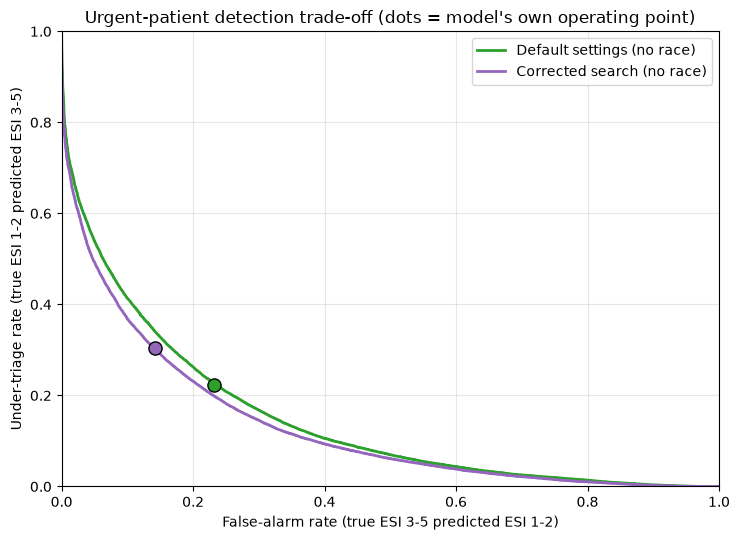

                     model  AUC_urgent_vs_non-urgent  actual_under_triage  actual_false_alarm  false_alarm_at_under_0.223  false_alarm_at_under_0.150
Default settings (no race)                    0.8552                0.223               0.231                       0.237                       0.324
Corrected search (no race)                    0.8702                0.304               0.142                       0.208                       0.293


In [35]:
#Question: is the corrected model really better, or did it just move to a different operating point?
# Needs: model_norace (default no-race model), final (corrected tuned model), X_te_nr, y_test
#This cell compares how well the default model and the corrected tuned model distinguish urgent patients (ESI 1–2) from non-urgent patients (ESI 3–5).
# operating point 

import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
 
yt = y_test.to_numpy() # converts the test labels (y_test) to a NumPy array for further processing.
urgent = yt <= 2                                           # urgent is a boolean array indicating which test samples are considered urgent (ESI 1 or 2).
models = {"Default settings (no race)": (model_norace, "tab:green"),
          "Corrected search (no race)": (final, "tab:purple")}
 
fig, ax = plt.subplots(figsize=(7.5, 5.5)) # creates a new figure and axes for plotting the ROC curves of the two models. The figure size is set to 7.5 inches wide by 5.5 inches tall.
rows = []
for name, (m, colour) in models.items():
    proba = m.predict_proba(X_te_nr)                       # predicts the class probabilities for each test sample using the current model m. The output is a 2D array where each row corresponds to a test sample and each column corresponds to the predicted probability of that sample belonging to each ESI class.
    p_urgent = proba[:, 0] + proba[:, 1]                   # p_urgent calculates the predicted probability of each test sample being urgent (ESI 1 or 2) by summing the probabilities of the first two classes (columns 0 and 1) from the predicted probabilities array proba.
    fpr, tpr, _ = roc_curve(urgent, p_urgent)              # computes the false positive rate (fpr) and true positive rate (tpr) for different threshold values using the roc_curve function from scikit-learn. It takes the true labels (urgent) and the predicted probabilities (p_urgent) as inputs. The third output (_) is an array of threshold values, which is not used in this case.
    under, false_alarm = 1 - tpr, fpr                      # under-triage vs non-urgent flagged urgent
    ax.plot(false_alarm, under, color=colour, linewidth=2, label=name)
 
    pred = proba.argmax(axis=1) + 1                        # pred is the predicted ESI level for each test sample, obtained by selecting the class with the highest predicted probability. The +1 is added because the ESI levels are 1-indexed (1 to 5) while the array indices are 0-indexed (0 to 4).
    op_under = float((pred[urgent] >= 3).mean())
    op_fa = float((pred[~urgent] <= 2).mean())
    ax.scatter([op_fa], [op_under], color=colour, s=90, edgecolor="black", zorder=3)
 
    order = np.argsort(under)                              # false-alarm rate needed to reach a given under-triage rate
    fa_at = lambda target: float(np.interp(target, under[order][::-1][::-1], false_alarm[order]))
    rows.append({"model": name, "AUC_urgent_vs_non-urgent": round(roc_auc_score(urgent, p_urgent), 4),
                 "actual_under_triage": round(op_under, 3), "actual_false_alarm": round(op_fa, 3),
                 "false_alarm_at_under_0.223": round(fa_at(0.223), 3),
                 "false_alarm_at_under_0.150": round(fa_at(0.150), 3)})
 
ax.set_xlabel("False-alarm rate (true ESI 3-5 predicted ESI 1-2)")
ax.set_ylabel("Under-triage rate (true ESI 1-2 predicted ESI 3-5)")
ax.set_title("Urgent-patient detection trade-off (dots = model's own operating point)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig("figure_operating_points.png", dpi=300, bbox_inches="tight")
plt.show()
print(pd.DataFrame(rows).to_string(index=False))
 

### The figure shows the trade-off between missing urgent patients and over-flagging non-urgent patients for the two models.

- X-axis — False-alarm rate: the share of ESI 3–5 patients incorrectly flagged as urgent (ESI 1–2).
- Y-axis — Under-triage rate: the share of urgent ESI 1–2 patients incorrectly predicted as non-urgent (ESI 3–5).
- Green and purple curves: the trade-off at different probability cutoffs for calling a patient urgent. A point nearer the bottom-left is generally preferable: fewer missed urgent patients and fewer false alarms.
- Dots: each model’s result using its usual multiclass prediction rule—not a selected cutoff on the curve.

	                                                         Default     	      Corrected
AUC, urgent vs non-urgent	                                0.855	                    0.870
Actual under-triage / false alarms	                        22.3% / 23.1%	    30.4% / 14.2%
False alarms when under-triage is held at 22.3%             23.7%	                    20.8%
False alarms when under-triage is held at 15%	            32.4%	                    29.3%

In this plot, the purple curve is generally below the green one, suggesting the corrected model can have a lower under-triage rate at similar false-alarm rates across many cutoffs. But at the models’ own prediction-rule dots, the corrected model is more conservative about flagging urgency: it has fewer false alarms, but misses a larger share of urgent patients than the default model.

So the corrected model may rank cases better across cutoffs, while its current prediction rule makes a different trade-off. The printed metrics and the chosen operating point matter when deciding which model is preferable—especially because under-triage can be consequential.

In [36]:
# operation points validation: compare the default model with the tuned model, using the same test set. The tuned model should have a lower under-triage rate for the same false-alarm rate.
import os
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedGroupKFold

configs = {
    "Default settings (no race)": ({}, 1.0),
    "Corrected search (no race)": ({"subsample": 0.85, "reg_lambda": 5, "n_estimators": 200,
                                    "min_child_weight": 10, "max_depth": 6, "learning_rate": 0.3,
                                    "colsample_bytree": 1.0}, 0.25),
}
TARGETS = [0.25, 0.20, 0.15, 0.10]     # share of urgent (ESI 1-2) patients we accept to miss

train_groups = pd.read_csv("x_train_clean.csv", usecols=["subject_id_x"])["subject_id_x"].to_numpy()
ytr = y_train_xgb.to_numpy()                                   # labels 0-4 (ESI 1-5)
assert len(train_groups) == len(ytr) == X_tr_nr.shape[0]

fit_idx, val_idx = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7)
                        .split(X_tr_nr, ytr, train_groups))   # patients never on both sides

urgent_val = ytr[val_idx] <= 1       # train labels are 0-4, so <= 1 means ESI 1-2
yt = y_test.to_numpy()
urgent_test = yt <= 2                # test labels are 1-5, so <= 2 means ESI 1-2
print("urgent share (validation, test):", round(urgent_val.mean(), 3), round(urgent_test.mean(), 3))  # both about 0.39

rows, scores = [], {}
for name, (params, power) in configs.items():
    share = np.bincount(ytr[fit_idx], minlength=5) / len(fit_idx)
    w = (1 / share[ytr[fit_idx]]) ** power
    model = XGBClassifier(objective="multi:softprob", tree_method="hist", random_state=42,
                          n_jobs=-1, **params)
    model.fit(X_tr_nr[fit_idx], ytr[fit_idx], sample_weight=w)
    s_val = model.predict_proba(X_tr_nr[val_idx])[:, :2].sum(axis=1)
    s_test = model.predict_proba(X_te_nr)[:, :2].sum(axis=1)
    scores[name.split(" (")[0].replace(" ", "_")] = s_test
    for target in TARGETS:
        cut = np.quantile(s_val[urgent_val], target)           # cutoff chosen on validation patients only
        rows.append({"model": name, "target_under_triage": target, "cutoff": round(float(cut), 4),
                     "val_under_triage": round(float((s_val[urgent_val] < cut).mean()), 3),
                     "test_under_triage": round(float((s_test[urgent_test] < cut).mean()), 3),
                     "test_false_alarm": round(float((s_test[~urgent_test] >= cut).mean()), 3)})
    print("fitted:", name)

op = pd.DataFrame(rows)
os.makedirs("results", exist_ok=True)
op.to_csv("results/operating_points_validation_based.csv", index=False)
np.savez("results/operating_point_scores.npz", y_true=yt, **scores)
print(op.to_string(index=False))

urgent share (validation, test): 0.391 0.391
fitted: Default settings (no race)
fitted: Corrected search (no race)
                     model  target_under_triage  cutoff  val_under_triage  test_under_triage  test_false_alarm
Default settings (no race)                 0.25  0.5092              0.25              0.248             0.212
Default settings (no race)                 0.20  0.4343              0.20              0.199             0.262
Default settings (no race)                 0.15  0.3423              0.15              0.147             0.329
Default settings (no race)                 0.10  0.2587              0.10              0.098             0.423
Corrected search (no race)                 0.25  0.4559              0.25              0.253             0.180
Corrected search (no race)                 0.20  0.3987              0.20              0.202             0.228
Corrected search (no race)                 0.15  0.3268              0.15              0.151             0.2

In [ ]:
# race_under_triage_comparison.
# Shows, in one table, the under-triage of true ESI 1-2 patients by race group for three models,
# plus the arithmetic behind the gaps (Black-White, Hispanic-White) and the "rise" caused by tuning.

import numpy as np
import pandas as pd

files = {"Default, with race": "hybrid_weighted",
         "Default, no race": "hybrid_norace",
         "Tuned, no race": "hybrid_norace_tuned_v2"}

x = pd.read_csv("x_test_clean.csv")
patients = pd.read_csv("patients.csv")
y = pd.read_csv("y_test_clean.csv").squeeze("columns").astype(int).to_numpy()
x["visit_year"] = pd.to_datetime(x["intime"]).dt.year
x = x.merge(patients[["subject_id", "anchor_age", "anchor_year"]],
            left_on="subject_id_x", right_on="subject_id", how="left")
assert len(x) == len(y) == 83620, "merge changed the number of rows"
valid = (x["anchor_age"] + (x["visit_year"] - x["anchor_year"])).notna().to_numpy()   # the 83,609 stays with an age

d = x.loc[valid].copy().reset_index(drop=True)
d["true_esi"] = y[valid]
race_cols = [c for c in d.columns if c.startswith("race_") and pd.api.types.is_numeric_dtype(d[c])]
raw = d[race_cols].idxmax(axis=1).str.replace("race_", "", regex=False)
def race_group(s):
    if s.startswith("WHITE"): return "White"
    if s.startswith("BLACK"): return "Black/African American"
    if s.startswith("HISPANIC") or s.startswith("SOUTH AMERICAN"): return "Hispanic/Latino"
    if s.startswith("ASIAN") or s.startswith("NATIVE HAWAIIAN"): return "Asian/Pacific Islander"
    return "Other/Unknown"
d["race_group"] = raw.map(race_group)

for name, f in files.items():
    z = np.load(f"results/{f}.npz")
    assert np.array_equal(z["y_true"].astype(int), y), f"{f}: saved labels differ from y_test_clean.csv"
    d[name] = z["y_pred"].astype(int)[valid]

urg = d[d["true_esi"] <= 2]                                  # urgent patients only
table = pd.DataFrame({name: (urg[name] >= 3).groupby(urg["race_group"]).mean() * 100 for name in files})
table.insert(0, "n_urgent", urg.groupby("race_group").size())
table["Rise: tuned minus default (no race)"] = table["Tuned, no race"] - table["Default, no race"]
print("Under-triage of true ESI 1-2 patients (%) and the rise caused by tuning (percentage points):")
print(table.round(1).to_string())

gaps = pd.DataFrame({name: table[name] - table.loc["White", name] for name in files})
print("\nGap to White patients (percentage points) = group rate minus White rate:")
print(gaps.drop(index="White").round(1).to_string())

Under-triage of true ESI 1-2 patients (%) and the rise caused by tuning (percentage points):
                        n_urgent  Default, with race  Default, no race  Tuned, no race  Rise: tuned minus default (no race)
race_group                                                                                                                 
Asian/Pacific Islander      1291                24.4              23.2            29.8                                  6.6
Black/African American      6017                26.5              23.9            32.3                                  8.4
Hispanic/Latino             1968                28.6              26.9            36.1                                  9.2
Other/Unknown               2400                22.6              21.5            27.4                                  5.9
White                      21006                20.3              21.5            29.7                                  8.2

Gap to White patients (percentage poin

In [37]:
# Equity fixed operating point: compare under-triage and false-alarm rates by sex, race, and age band. This cell evaluates the equity of the tuned model without race features at a fixed operating point (cutoff) that achieves a target under-triage rate of 15% on the validation set. It calculates under-triage and false-alarm rates for different demographic groups (sex, race, age band) and saves the results to a CSV file.
# If we tune the model so that it misses about 15% of really urgent patients (under-triage target = 0.15), are the under-triage and false-alarm rates similar across sex, race, and age groups?”
# results   18-34      5824         0.200 and Female     16554         0.170 0.164-0.175             0.171        0.277 Male     16128         0.132 0.126-0.137 
import pandas as pd
 
TARGET = 0.15
MODELS = {"Default settings (no race)": "Default_settings", "Corrected search (no race)": "Corrected_search"}
 # 
op = pd.read_csv("results/operating_points_validation_based.csv")
sc = np.load("results/operating_point_scores.npz")
x = pd.read_csv("x_test_clean.csv")
patients = pd.read_csv("patients.csv")
y = pd.read_csv("y_test_clean.csv").squeeze("columns").astype(int).to_numpy()
assert np.array_equal(sc["y_true"].astype(int), y), "saved labels differ from y_test_clean.csv"
 
x["visit_year"] = pd.to_datetime(x["intime"]).dt.year
x = x.merge(patients[["subject_id", "anchor_age", "anchor_year"]],
            left_on="subject_id_x", right_on="subject_id", how="left")
assert len(x) == len(y) == 83620, "merge changed the number of rows"
x["age_at_visit"] = x["anchor_age"] + (x["visit_year"] - x["anchor_year"])
valid = x["age_at_visit"].notna().to_numpy()
 # valid = x["age_at_visit"].notna().to_numpy() creates a boolean array indicating which rows in the DataFrame x have valid (non-missing) values for the "age_at_visit" column. This is important for subsequent analyses that require age information, as it allows the code to filter out any rows with missing age data before performing calculations or generating summaries.

#creates demographic group columns: sex, race_group, and age_band. These columns are derived from the existing data in the DataFrame x and are used for subgroup analyses of under-triage and false-alarm rates.
d = x.loc[valid].copy().reset_index(drop=True)
d["true_esi"] = y[valid]
d["age_band"] = pd.cut(d["age_at_visit"], bins=[18, 35, 50, 65, 80, 103],
                       labels=["18-34", "35-49", "50-64", "65-79", "80+"], include_lowest=True)
d["sex"] = d["gender"].map({0: "Male", 1: "Female"})
race_cols = [c for c in d.columns if c.startswith("race_") and pd.api.types.is_numeric_dtype(d[c])] # race_cols = [c for c in d.columns if c.startswith("race_") and pd.api.types.is_numeric_dtype(d[c])] identifies all columns in the DataFrame d that represent race information. It filters the columns to include only those that start with "race_" and are of a numeric data type. This is important for subsequent analyses that involve race, as it allows the code to focus on relevant columns that contain race-related data for subgroup analyses of under-triage and false-alarm rates.
race_raw = d[race_cols].idxmax(axis=1).str.replace("race_", "", regex=False)  
def race_group(s):
    if s.startswith("WHITE"): return "White"
    if s.startswith("BLACK"): return "Black/African American"
    if s.startswith("HISPANIC") or s.startswith("SOUTH AMERICAN"): return "Hispanic/Latino"
    if s.startswith("ASIAN") or s.startswith("NATIVE HAWAIIAN"): return "Asian/Pacific Islander"
    return "Other/Unknown"
d["race_group"] = race_raw.map(race_group)
 
def wilson(k, n, z=1.96): # calculates the Wilson score interval for a binomial proportion. It takes the number of successes (k), the total number of trials (n), and an optional z-score (default is 1.96 for a 95% confidence interval) as inputs. The function returns the lower and upper bounds of the confidence interval for the proportion of successes. This is useful for estimating the uncertainty around proportions, such as under-triage rates or false-alarm rates, in subgroup analyses.
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (centre - half, centre + half)
 
all_rows = []
for name, key in MODELS.items():
    cut = float(op[(op["model"] == name) & (op["target_under_triage"] == TARGET)]["cutoff"].iloc[0])
    d["flag_urgent"] = sc[key][valid] >= cut # d["flag_urgent"] = sc[key][valid] >= cut creates a new boolean column "flag_urgent" in the DataFrame d. This column indicates whether each patient is flagged as urgent (predicted ESI 1-2) based on the model's predicted probability scores (sc[key]) and the cutoff value (cut) determined for the target under-triage rate (TARGET). If the predicted score for a patient is greater than or equal to the cutoff, they are flagged as urgent (True); otherwise, they are not flagged (False).
    urg = d[d["true_esi"] <= 2]         # urgent patients = true_esi <= 2; urg = d[d["true_esi"] <= 2] creates a new DataFrame urg that contains only the rows from d where the true ESI is 1 or 2 (urgent patients). This subset is used to analyze the under-triage rates and other metrics specifically for urgent patients, allowing for a focused evaluation of the model's performance in identifying those who require immediate attention.
    age_w = urg["age_band"].value_counts(normalize=True)
    print(f"\n######## {name} | cutoff {cut} | overall under-triage "
          f"{(~urg['flag_urgent']).mean():.3f}, false alarms {d.loc[d.true_esi >= 3, 'flag_urgent'].mean():.3f}")  #under_triage = (~flag_urgent) among urgent cases and false_alarm = flag_urgent among non-urgent cases
    for col in ["sex", "race_group", "age_band"]:
        rows = []
        for g, dg in d.groupby(col, observed=True): # loops through each demographic group (sex, race_group, age_band) and calculates under-triage and false-alarm rates for each group. It groups the DataFrame d by the current demographic column (col) and iterates over each group (g) and its corresponding subset of data (dg). For each group, it calculates the number of urgent patients (n_urgent), the number of under-triaged urgent patients (miss), the Wilson score confidence interval for the under-triage rate, the age-standardized under-triage rate, and the false-alarm rate among non-urgent patients. The results are stored in a list of dictionaries (rows) for later conversion to a DataFrame.
            u, nu = dg[dg["true_esi"] <= 2], dg[dg["true_esi"] >= 3]
            miss = int((~u["flag_urgent"]).sum())
            lo, hi = wilson(miss, len(u))
            by_age = u.groupby("age_band", observed=True)["flag_urgent"].apply(lambda s: (~s).mean())
            w = age_w.reindex(by_age.index) # reindexes the age weights (w) to match the index of the by_age Series, which contains the under-triage rates for each age band. This ensures that the weights are aligned with the corresponding age bands when calculating the age-standardized under-triage rate. The reindexing fills any missing age bands with NaN, allowing for accurate calculations in the next step.
            rows.append({"model": name, col: g, "n_urgent": len(u),
                         "under_triage": round(miss / len(u), 3), "95%CI": f"{lo:.3f}-{hi:.3f}",
                         "age_standardised": round(float((by_age * w / w.sum()).sum()), 3),
                         "false_alarm": round(float(nu["flag_urgent"].mean()), 3)})
        table = pd.DataFrame(rows)
        print(f"\n--- by {col} ---")
        print(table.drop(columns="model").to_string(index=False))
        all_rows.append(table.rename(columns={col: "group"}).assign(variable=col))
 
import os
os.makedirs("results", exist_ok=True)
pd.concat(all_rows).to_csv("results/equity_fixed_operating_point.csv", index=False)


######## Default settings (no race) | cutoff 0.3423 | overall under-triage 0.147, false alarms 0.329

--- by sex ---
   sex  n_urgent  under_triage       95%CI  age_standardised  false_alarm
Female     16554         0.159 0.153-0.164             0.160        0.319
  Male     16128         0.135 0.130-0.141             0.135        0.341

--- by race_group ---
            race_group  n_urgent  under_triage       95%CI  age_standardised  false_alarm
Asian/Pacific Islander      1291         0.156 0.138-0.177             0.150        0.271
Black/African American      6017         0.155 0.146-0.164             0.149        0.314
       Hispanic/Latino      1968         0.176 0.160-0.193             0.158        0.270
         Other/Unknown      2400         0.147 0.133-0.161             0.136        0.315
                 White     21006         0.142 0.137-0.146             0.146        0.353

--- by age_band ---
age_band  n_urgent  under_triage       95%CI  age_standardised  false_alarm


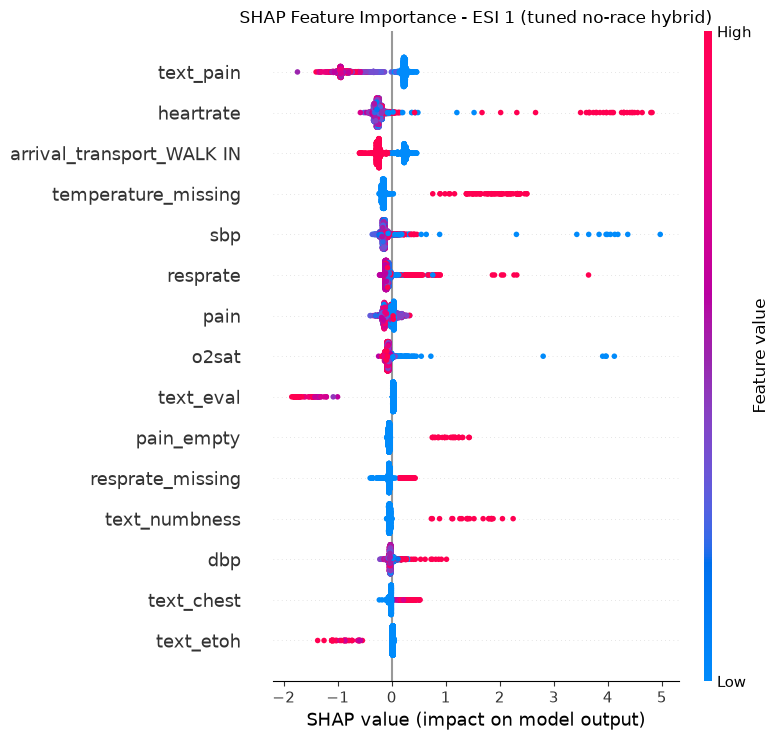

Saved shap_esi1_tuned_norace.png


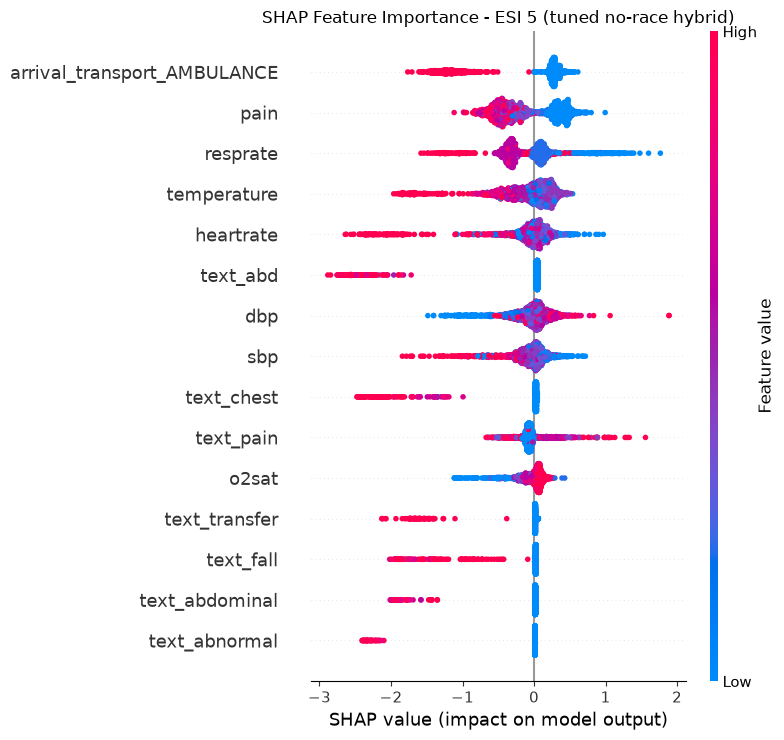

Saved shap_esi5_tuned_norace.png


In [ ]:
# This cell calculates and plots SHAP explanations for the final tuned hybrid model without race features. 
# In broad terms, it asks: for each prediction, which input features pushed the model toward ESI 1 or ESI 5, and how much

import numpy as np
import matplotlib.pyplot as plt
import shap
from scipy.sparse import issparse # issparse checks whether the feature matrix uses compact sparse storage.

# final: the fitted, tuned no-race model.
# X_te_nr: test features with race columns removed.
# tfidf: the fitted text-feature transformer, used to get text feature names.
# st_tr: the structured training features after removing race columns.
# globals() lists variables currently available in the notebook’s Python session. If any are missing, the cell raises an error that tells you to run the prerequisite cells firs
required = ("final", "X_te_nr", "tfidf", "st_tr") 
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "Run the preceding preprocessing and tuned-model training cells first; "
        f"missing variables: {', '.join(missing)}"
    )

# The model’s input matrix combines text features and structured features. This builds matching labels for both parts.
#  The text_ prefix distinguishes words from structured features that might otherwise share the same name.
text_feature_names = [f"text_{name}" for name in tfidf.get_feature_names_out()]
structured_feature_names_nr = st_tr.columns.tolist()
feature_names_nr = text_feature_names + structured_feature_names_nr

# Verify that the data really is no-race and the labels match
if any(name.startswith("race_") for name in structured_feature_names_nr): # This guards against accidentally using race columns.
    raise ValueError("The tuned no-race SHAP features unexpectedly contain race columns.")
if len(feature_names_nr) != X_te_nr.shape[1]: # Every model input column must have exactly one feature name. This check catches a mismatch before the plot could show misleading labels.
    raise ValueError(
        f"Feature-name count ({len(feature_names_nr)}) does not match "
        f"the no-race matrix width ({X_te_nr.shape[1]})."
    )

# Choose a sample and calculate SHAP values
# The cell explains up to 2,000 test examples; if there are fewer, it uses all of them. 
# TreeExplainer is SHAP’s explainer for tree-based models such as XGBoost. It calculates each feature’s contribution to each example’s prediction.
sample_size = min(2000, X_te_nr.shape[0])
x_sample_nr = X_te_nr[:sample_size]
explainer_nr = shap.TreeExplainer(final)
shap_values_nr = explainer_nr.shap_values(x_sample_nr)

# Handle SHAP’s multiclass output formats
# The if/else block checks the format and organizes the values into class_shap_values, with one set of feature contributions per ESI class. 
# If SHAP returns an unexpected format, it raises an error rather than plotting potentially incorrect results.
if isinstance(shap_values_nr, list):
    if len(shap_values_nr) != 5:
        raise ValueError(f"Expected SHAP values for 5 ESI classes; got {len(shap_values_nr)}.")
    class_shap_values = shap_values_nr
else:
    values = np.asarray(shap_values_nr)
    if values.shape == (sample_size, X_te_nr.shape[1], 5):
        class_shap_values = [values[:, :, class_index] for class_index in range(5)]
    elif values.shape == (5, sample_size, X_te_nr.shape[1]):
        class_shap_values = [values[class_index, :, :] for class_index in range(5)]
    else:
        raise ValueError(f"Unexpected multiclass SHAP output shape: {values.shape}.")

# Convert data for plotting
x_sample_dense = x_sample_nr.toarray() if issparse(x_sample_nr) else np.asarray(x_sample_nr)
for class_index, esi in ((0, 1), (4, 5)): #  Plot ESI 1 and ESI 5
    shap.summary_plot(      # creates a summary of the most influential features across the selected example
        class_shap_values[class_index],
        x_sample_dense,
        feature_names=feature_names_nr,
        max_display=15,   #max_display=15 limits the chart to the top 15 features.
        show=False,
    )
    plt.title(f"SHAP Feature Importance - ESI {esi} (tuned no-race hybrid)")
    plt.tight_layout()
    output_path = f"shap_esi{esi}_tuned_norace.png"
    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"Saved {output_path}")

### These plots show which features help the model choose ESI1 AND ESI5. Each dot is one patient example.

- Right of zero: the feature pushed the model toward that ESI class.
- Left of zero it pushed the model away from that class.
- Pink/Blue higher/lower feature value. For text features, pink generally means the word was present and blue means it was absent.

### ESI 1 plot
The model’s strongest signals include pain-related text, heart rate, and arrival as a walk-in. For example, when the word *pain* appears, its dots are mostly left of zero, so it often pushes the model away from ESI 1. Some high heart-rate examples push it toward ESI 1. Missing temperature also pushes toward ESI 1 in some examples.

### ESI 5 plot
The strongest signals are arrival by ambulance, pain, and vital signs such as respiratory rate, temperature, and heart rate. The ambulance feature’s pink dots are mostly left of zero, meaning ambulance arrival generally pushes the model away from ESI 5. Several complaint words—such as abdominal, chest, and fall—also tend to push away from ESI 5.

### Main difference
The model relies on different clues for these two classes. For ESI 1, pain-related text, heart rate, and walk-in arrival stand out. For ESI 5, ambulance arrival and a broader set of vital signs and complaint words stand out.

These show patterns learned by the model, not proof that a feature causes a particular triage level or that the model is clinically correct.

In [39]:
 # bootstrap confidence intervals
 # this cell is a bootstrap uncertainty analysis for several model variants.
 # Compare models not just by a single point estimate, but by a 95% confidence interval.
# It also checks whether the differences between specific models are likely to be real, rather than random noise.
# results F1 of 0.5527 (95% CI 0.540–0.565)

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
 
B = 500                                   # bootstrap repeats (use 1000 if time allows)
files = {"Text-only (TF-IDF)": "text_only", "Structured, unweighted": "structured_unweighted",
         "Structured, class-weighted": "structured_weighted", "Structured, tuned": "structured_tuned",
         "Hybrid, default (with race)": "hybrid_weighted", "Hybrid, default (no race)": "hybrid_norace",
         "Hybrid, tuned (no race)": "hybrid_norace_tuned_v2"}
 
pred, yt = {}, None
for name, f in files.items():
    z = np.load(f"results/{f}.npz") # predictions saved in a .npz file for each model variant. The file contains the true labels (y_true) and predicted labels (y_pred) for the test set.
    yt = z["y_true"].astype(int)   # yt = z["y_true"].astype(int) converts the true labels (y_true) from the .npz file to an integer NumPy array. This is necessary for evaluating the performance of the model variants in the subsequent analysis.
    pred[name] = z["y_pred"].astype(int)  # pred[name] = z["y_pred"].astype(int) stores the predicted labels (y_pred) from the .npz file as an integer NumPy array in the pred dictionary, using the model name as the key. This allows for easy access to the predictions of each model variant during the bootstrap analysis.
urgent = yt <= 2  # This means “true urgent” patients are those with ESI 1 or 2.
 
patient = pd.read_csv("x_test_clean.csv", usecols=["subject_id_x"])["subject_id_x"].to_numpy()
assert len(patient) == len(yt) == 83620
codes, uniq = pd.factorize(patient)       # one code per patient, so repeat visits stay together
rng = np.random.default_rng(42)
 
f1_b = {n: [] for n in pred} # f1_b = {n: [] for n in pred} initializes a dictionary to store the bootstrap F1 scores for each model variant. The keys of the dictionary are the model names (from the pred dictionary), and the values are empty lists that will be populated with F1 scores calculated during the bootstrap resampling process. This allows for the collection of F1 scores across multiple bootstrap iterations for each model, which can later be used to compute confidence intervals and assess the variability of model performance.
ut_b = {n: [] for n in pred}  # ut_b = {n: [] for n in pred} initializes a dictionary to store the bootstrap under-triage rates for each model variant. Similar to f1_b, the keys of the dictionary are the model names (from the pred dictionary), and the values are empty lists that will be populated with under-triage rates calculated during the bootstrap resampling process. This allows for the collection of under-triage rates across multiple bootstrap iterations for each model, which can later be used to compute confidence intervals and assess the variability of model performance in terms of under-triage.
for b in range(B): # loops through B bootstrap iterations (in this case, 500 iterations). In each iteration, a new bootstrap sample of patients is drawn with replacement, and the F1 scores and under-triage rates are calculated for each model variant based on this resampled data. The results are stored in the f1_b and ut_b dictionaries for later analysis.
    counts = rng.multinomial(len(uniq), np.full(len(uniq), 1 / len(uniq)))   # patients drawn with replacement
    w = counts[codes].astype(float)                                          # how often each visit appears
    for n, yp in pred.items():
        f1_b[n].append(f1_score(yt, yp, average="macro", sample_weight=w))
        ut_b[n].append(np.average(yp[urgent] >= 3, weights=w[urgent]))
 
def ci(a):  # ci(a) is a function that calculates the 95% confidence interval for a given array of values (a). It uses the numpy.percentile function to compute the lower and upper bounds of the confidence interval based on the 2.5th and 97.5th percentiles of the input array. The function returns a formatted string representing the confidence interval in the form "lower_bound-upper_bound", rounded to three decimal places. This is useful for summarizing the uncertainty around performance metrics such as F1 scores and under-triage rates obtained from bootstrap resampling.
    lo, hi = np.percentile(a, [2.5, 97.5]) 
    return f"{lo:.3f}-{hi:.3f}"
 
rows = []
for n, yp in pred.items():  # loops through each model variant (n) and its corresponding predicted labels (yp) in the pred dictionary. For each model, it calculates the macro F1 score and under-triage rate using the true labels (yt) and the predicted labels (yp). It also computes the 95% confidence intervals for both metrics using the bootstrap results stored in f1_b and ut_b. The results are stored in a list of dictionaries (rows) for later conversion to a DataFrame, which will be printed to summarize the performance of each model variant along with their confidence intervals.
    rows.append({"model": n, "macro_F1": round(f1_score(yt, yp, average="macro"), 4), "F1_95CI": ci(f1_b[n]),
                 "under_triage": round(float((yp[urgent] >= 3).mean()), 3), "UT_95CI": ci(ut_b[n])})
print(pd.DataFrame(rows).to_string(index=False))
 
pairs = [("Hybrid, tuned (no race)", "Hybrid, default (no race)"),
         ("Hybrid, tuned (no race)", "Structured, tuned"),
         ("Hybrid, default (no race)", "Hybrid, default (with race)"),
         ("Structured, tuned", "Structured, unweighted"),
         ("Text-only (TF-IDF)", "Structured, unweighted")]
prow = []
for a, c in pairs:
    d_f1 = np.array(f1_b[a]) - np.array(f1_b[c])
    d_ut = np.array(ut_b[a]) - np.array(ut_b[c])
    prow.append({"A minus B": f"{a}  -  {c}", # prow.append({"A minus B": f"{a}  -  {c}", creates a dictionary for each pair of models being compared. The key "A minus B" contains a string that describes the comparison between model A and model C (e.g., "Hybrid, tuned (no race) - Hybrid, default (no race)"). This dictionary will also include the mean differences in macro F1 scores and under-triage rates, along with their respective 95% confidence intervals.
                 "macro_F1_diff": round(float(np.mean(d_f1)), 4), "F1_diff_95CI": ci(d_f1),
                 "under_triage_diff": round(float(np.mean(d_ut)), 3), "UT_diff_95CI": ci(d_ut)})
print("\nPaired differences (an interval that excludes 0 = a real difference):")
print(pd.DataFrame(prow).to_string(index=False)) 
 

                      model  macro_F1     F1_95CI  under_triage     UT_95CI
         Text-only (TF-IDF)    0.3656 0.362-0.370         0.247 0.241-0.253
     Structured, unweighted    0.3689 0.366-0.372         0.533 0.526-0.540
 Structured, class-weighted    0.3485 0.345-0.352         0.365 0.358-0.372
          Structured, tuned    0.4020 0.398-0.407         0.371 0.364-0.377
Hybrid, default (with race)    0.4641 0.460-0.469         0.223 0.216-0.228
  Hybrid, default (no race)    0.4625 0.458-0.467         0.223 0.217-0.229
    Hybrid, tuned (no race)    0.5527 0.540-0.565         0.304 0.297-0.310

Paired differences (an interval that excludes 0 = a real difference):
                                                A minus B  macro_F1_diff F1_diff_95CI  under_triage_diff  UT_diff_95CI
    Hybrid, tuned (no race)  -  Hybrid, default (no race)         0.0899  0.078-0.102              0.080   0.077-0.085
            Hybrid, tuned (no race)  -  Structured, tuned         0.1502  0.138-0.1

Tuned hybrid (no race): Brier = 0.1406 | expected calibration error = 0.020 | mean predicted P(urgent) = 0.408 vs observed urgent share = 0.391
Default hybrid (no race): Brier = 0.1519 | expected calibration error = 0.047 | mean predicted P(urgent) = 0.438 vs observed urgent share = 0.391


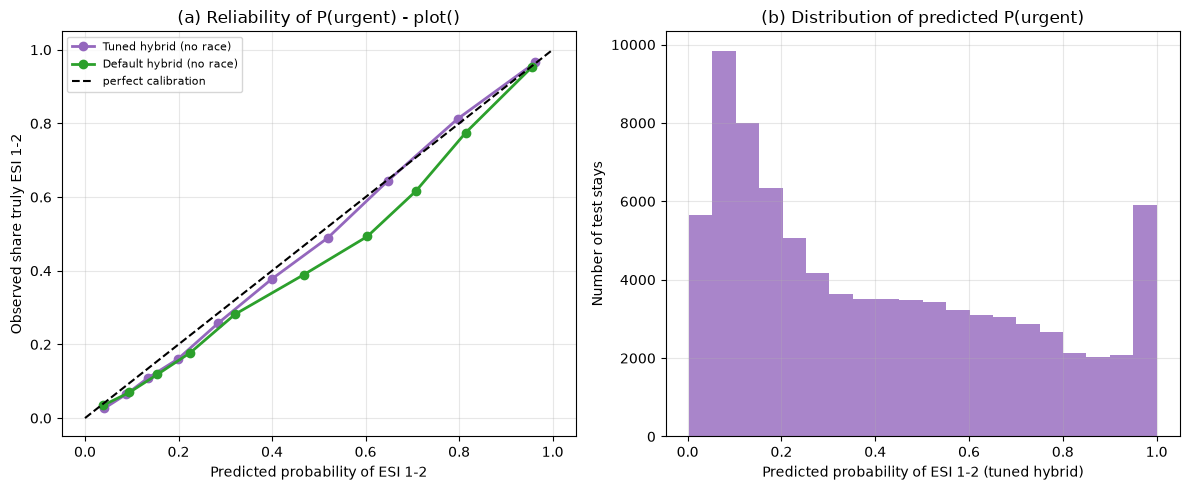


Per class: actual share vs average predicted probability (tuned hybrid)
 ESI  actual_share  mean_predicted_prob
   1         0.057                0.071
   2         0.333                0.337
   3         0.538                0.494
   4         0.068                0.092
   5         0.003                0.006


In [40]:
# calibration of the tuned hybrid's probabilities
# checkING how well the tuned hybrid model’s predicted probabilities are calibrated.
# The model does not only output a class label. It outputs a probability for each ESI category (1–5).
# when the model says “there is a 70% chance this patient is urgent,” does that actually happen about 70% of the time?

import os
import matplotlib.pyplot as plt
 
proba = np.load("results/hybrid_norace_tuned_v2_proba.npy")             # proba = np.load("results/hybrid_norace_tuned_v2_proba.npy") loads the predicted probabilities for the tuned hybrid model without race features from a .npy file. The array proba contains the predicted probabilities for each class (ESI 1-5) for each test sample. This is used to assess the calibration of the model's probability estimates, which is important for understanding how well the predicted probabilities align with the actual observed outcomes.
assert proba.shape == (len(yt), 5)          # assert proba.shape == (len(yt), 5) checks that the shape of the predicted probabilities array matches the expected shape (number of test samples by number of classes).
p_urg = proba[:, :2].sum(axis=1)                                          # p_urg = proba[:, :2].sum(axis=1) calculates the predicted probability of each test sample being urgent (ESI 1 or 2) by summing the probabilities of the first two classes (columns 0 and 1) from the predicted probabilities array proba. The result is a 1D array containing the predicted probabilities of urgency for each test sample, which will be used for calibration analysis.
curves = {"Tuned hybrid (no race)": p_urg}    # creates a dictionary named curves that contains the predicted probabilities of urgency (p_urg) for the tuned hybrid model without race features. The key "Tuned hybrid (no race)" is used to label the model in subsequent analyses, such as reliability plots and calibration assessments. This allows for easy comparison of the tuned hybrid model's performance against other models or configurations.
if "model_norace" in globals() and "X_te_nr" in globals():               # default model, if still in memory
    curves["Default hybrid (no race)"] = model_norace.predict_proba(X_te_nr)[:, :2].sum(axis=1)
 
def reliability(p, y_bin, bins=10):
    edges = np.unique(np.quantile(p, np.linspace(0, 1, bins + 1)))
    b = np.clip(np.digitize(p, edges[1:-1]), 0, len(edges) - 2)
    out = pd.DataFrame({"bin": b, "p": p, "y": y_bin}).groupby("bin").agg(n=("y", "size"), predicted=("p", "mean"),
                                                                       observed=("y", "mean"))
    ece = float((out["n"] / out["n"].sum() * (out["predicted"] - out["observed"]).abs()).sum()) # “How far are the model’s probability estimates from reality, overall?”
    return out, ece  # expected calibration error; this is a weighted average of absolute differences between predicted and observed rates
    # each bin, it computes:
    #n = number of cases in the bin
    #predicted = mean predicted probability in the bin
    #observed = observed share of truly urgent cases in that bin

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for (name, p), colour in zip(curves.items(), ["tab:purple", "tab:green"]):
    rel, ece = reliability(p, urgent.astype(int))
    brier = float(np.mean((p - urgent) ** 2))
    print(f"{name}: Brier = {brier:.4f} | expected calibration error = {ece:.3f} | "
          f"mean predicted P(urgent) = {p.mean():.3f} vs observed urgent share = {urgent.mean():.3f}")
    axes[0].plot(rel["predicted"], rel["observed"], marker="o", linewidth=2, color=colour, label=name)
axes[0].plot([0, 1], [0, 1], "k--", label="perfect calibration")
axes[0].set_xlabel("Predicted probability of ESI 1-2"); axes[0].set_ylabel("Observed share truly ESI 1-2")
axes[0].set_title("(a) Reliability of P(urgent) - plot()"); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)
axes[1].hist(p_urg, bins=20, color="tab:purple", alpha=0.8)
axes[1].set_xlabel("Predicted probability of ESI 1-2 (tuned hybrid)"); axes[1].set_ylabel("Number of test stays")
axes[1].set_title("(b) Distribution of predicted P(urgent)"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figure_calibration.png", dpi=300, bbox_inches="tight")
plt.show()
 
share = np.bincount(yt - 1, minlength=5) / len(yt) # This computes the actual proportion of each ESI level in the data
print("\nPer class: actual share vs average predicted probability (tuned hybrid)") # This checks whether the model’s average predicted probability per class matches the actual prevalence of each ESI class in the test set.
print(pd.DataFrame({"ESI": [1, 2, 3, 4, 5], "actual_share": share.round(3),
                    "mean_predicted_prob": proba.mean(axis=0).round(3)}).to_string(index=False))
 

# Figure above is a calibration check for the tuned hybrid model.

What the figure is showing

It has two panels:

- Left panel: reliability curve
  - x-axis = predicted probability of being urgent (ESI 1 or 2)
  - y-axis = observed proportion of patients who were actually urgent
  - dashed diagonal line is the ideal case: if the model says “70% urgent,” then about 70% of those cases should actually be urgent

- Right panel: histogram
  - shows how often the model assigns different urgency probabilities
  - tells you whether the model is mostly making moderate predictions or extreme predictions

What the printed output says

From the notebook output:

- Tuned hybrid (no race): Brier = 0.1406
- expected calibration error = 0.020
- mean predicted P(urgent) = 0.408
- observed urgent share = 0.391

Interpretation:

- Brier score = 0.1406
  - Lower is better.
  - This is fairly good for a probability model.
  - It means the model’s probability estimates are reasonably close to the true outcomes.

- ECE = 0.020
  - This is very low.
  - ECE is a calibration metric: it measures how different the predicted probabilities are from the real observed rates.
  - 0.020 means the model is quite well calibrated overall.

- Mean predicted urgent probability = 0.408
  - The model thinks about 40.8% of test patients are urgent on average.

- Observed urgent share = 0.391
  - In reality, about 39.1% are truly urgent.

So the model is slightly overestimating urgency overall by about 1.7 percentage points, but the difference is small.
How to read the left panel

If the reliability curve is close to the 45-degree line, the model is well calibrated.

In this figure, the curve is likely near the diagonal with only small deviations. That means:
This is exactly what “good calibration” looks like.

How to read the right panel

The histogram tells you the spread of predictions:

many patients get predicted urgency probabilities in the middle range
some are low-risk, some are high-risk
the model is not just predicting 0 or 1 all the time, which is good for probabilistic decision-making
In this case, the distribution is centered around 0.4, which matches the mean predicted risk of 0.408.

Why this matters clinically

This is important because the model is not just making a yes/no triage decision; it is also providing a probability of urgency.

If those probabilities are well calibrated, then clinicians can interpret the output more trustingly:

a patient with 0.80 predicted urgency is genuinely high risk

when the model says a patient has a 0.2 probability of being urgent, roughly 20% are actually urgent
when it says 0.5, roughly half are urgent
when it says 0.8, roughly 80% are urgent
a patient with 0.20 predicted urgency is genuinely low risk
the model’s uncertainty is meaningful rather than misleading


The last table compares the actual frequency of each ESI class with the model’s average predicted probability for that class across all test stays.

- ESI: the class, from 1 to 5.
- actual_share: the fraction of test stays whose true label is that ESI class. For example, 0.20 means 20% of stays were actually in that class.
- mean_predicted_prob: the average probability the model assigned to that class across all stays. For example, 0.18 means the model assigned that class 18% probability on average.

How to interpret each row:

- If the two values are close, the model’s overall probability assigned to that class roughly matches how often the class actually occurs.
- If mean_predicted_prob is higher than actual_share, the model assigns too much probability to that class on average.
- If it is lower, the model assigns too little probability to that class on average.

The values in each column should add up to approximately 1.0 (or 100%), allowing for rounding.

This is an overall, class-by-class calibration check. It does not tell you whether every individual prediction is reliable, or whether probabilities are equally calibrated across different patient groups. That’s why the reliability plot is useful as a complementary check.

Bottom line

This figure shows that the tuned hybrid model is fairly well calibrated:
- it predicts urgency with reasonable accuracy
- its probability estimates track actual urgent cases well
- it slightly overestimates urgency on average, but not by much
- overall, the calibration is good enough for probabilistic use
